# Multiclass Brain Tumor Classification From 2D MRI Slices: From a Baseline Network to Transfer Learning

## AAI 6640 Applied Deep Learning: Final Project Notebook (Midterm Checkpoint Version)

**Team (Group 2):** Kritika Jain, Chirag Arora, Dhrumil Shaileshkumar Khalas  
**Instructor:** Dr. Behnaz Merikhi  
**Project title:** Multiclass Brain Tumor Classification From 2D MRI Slices: From a Baseline Network to Transfer Learning  
**Dataset:** Brain Tumor Classification (MRI), Version 3, Kaggle (Bhuvaji et al., 2025), MIT license  
**Development environment:** Google Colab (GPU runtime), PyTorch  
**Last updated:** 2026-10-30

---

This notebook is the main technical record of our final project. This midterm version covers the progress overview, team records, data audit and cleaning, Stage 1 (foundational modeling), Stage 2 (optimization and diagnostic analysis), challenges, and the forward plan for Stage 3. We will keep developing this same notebook for the final submission.

## Notebook Roadmap

1. [Progress Overview](#1-progress-overview)
2. [Team Participation and Individual Contribution](#2-team-participation-and-individual-contribution)
3. [Environment and Reproducibility](#3-environment-and-reproducibility)
4. [Project Overview](#4-project-overview)
5. [Data Loading, Exploration, Cleaning, and Preparation](#5-data-loading-exploration-cleaning-and-preparation)
6. [Stage 1: Foundational Modeling](#6-stage-1-foundational-modeling)
7. [Stage 2: Optimization and Diagnostic Analysis](#7-stage-2-optimization-and-diagnostic-analysis)
8. [Challenges and Mitigation](#8-challenges-and-mitigation)
9. [Midterm Reflection and Forward Plan](#9-midterm-reflection-and-forward-plan)
10. [Stage 3: Architectural Specialization](#10-stage-3-architectural-specialization) *(after the midterm)*
11. [Final Comparison and Key Findings](#11-final-comparison-and-key-findings) *(after the midterm)*
12. [Limitations and Responsible Use](#12-limitations-and-responsible-use) *(after the midterm)*
13. [Project Reflection and Future Work](#13-project-reflection-and-future-work) *(after the midterm)*
14. [References](#14-references)
15. [Submission Checklists](#15-submission-checklists)

The course template sections are kept. We added three sections that the midterm checkpoint requires (Progress Overview, Team Participation, and Challenges and Mitigation) and renumbered the rest.

# 1. Progress Overview

## 1.1 Current Status

Since the proposal, we have completed Stage 1 and Stage 2 of the three-stage framework. The work done so far:

- **Data audit.** Class counts, image size and format survey, exact duplicate detection (MD5 file hashes), and near-duplicate detection (perceptual hashing).
- **Cleaning and a leakage-aware split.** Duplicates (including Testing copies of Training images) and label conflicts were removed **before** any split. Visually related images were grouped, and each group stays in one split of a new train, validation, and test split.
- **Reusable preprocessing.** Grayscale conversion, empty-border crop, square padding, resizing, and normalization with training statistics only.
- **Stage 1 baseline.** A fully connected MLP trained with three seeds and evaluated on the validation set.
- **Stage 2 experiments.** Three controlled experiments: dropout, weight decay, and a data-protocol (leakage) experiment.
- **Diagnostics.** Learning curves, confusion matrices, per-class metrics, tumor detection sensitivity and false negative rate per tumor type, calibration (reliability diagram and ECE), and a review of misclassified images.

**The test set has not been used for any model evaluation.** It is reserved for the final submission, so it stays an independent estimate of performance.

**Key numbers at the checkpoint:**

- **Cleaning:** 720 of 3,264 images removed (36 label conflicts and 684 redundant copies). 264 of the 394 Testing images (67%) turned out to be copies of Training images.
- **Split:** a cleaned pool of 2,544 images, split into 1,807 train, 358 validation, and 379 test images, with no related-image group crossing a split.
- **Baseline:** validation macro recall 0.733 ± 0.014 and tumor false negative rate 0.095 ± 0.027 (3 seeds). Meningioma is the weakest class (recall 0.569).
- **Stage 2:** neither stronger dropout nor weight decay beat the baseline, so the baseline configuration (dropout 0.25, no weight decay) is carried forward.
- **Leakage:** a naive random split of the raw data reports 0.806 macro recall, 0.073 higher than our clean protocol.
- **Shortcut:** 18 of the 31 tumors missed by the model (seed 42) are not 512 × 512, although only 10% of the validation tumor images have this format. Almost every no-tumor image (99%) is not 512 × 512.

The project is on schedule. Stage 3 (a custom CNN, then ResNet18 transfer learning) starts in Week 9.

## 1.2 Changes Since the Proposal

Most changes respond directly to the instructor's feedback on the proposal. The problem, dataset, and four-class task are unchanged.

| Area | Proposal (Week 4) | Now (Week 8) | Why |
|---|---|---|---|
| Order of cleaning | Deduplication listed as a preprocessing step | Exact duplicates, near duplicates, and label conflicts are removed, and similarity groups are built, **before** any split | Feedback: cleaning must come before the splits are finalized |
| Split strategy | Stratified 15% validation hold-out from Training; Testing folder as the test set | Stratified **group-aware** train / validation / test split (about 71 / 14 / 15%) of the cleaned images from **both** folders | No patient IDs, so groups approximate patient-level separation. The audit found that 67% of the Testing folder copies Training images, and the cleaned Testing folder had no no-tumor images left (Section 5.4.3) |
| Test set use | Compare raw vs deduplicated **test** performance (Objective 4) | Test set **not used** at the midterm; the raw vs clean comparison uses **validation** data only (Experiment 3) | Feedback: repeated test use breaks the independence of the final evaluation |
| Tumor detection metric | "Tumor detection sensitivity (tumors predicted as no tumor)" | Sensitivity = share of tumor images predicted as any tumor class; false negative rate (FNR) = share predicted as no tumor; both reported per tumor type | Feedback: tumors predicted as no tumor are false negatives, not sensitivity |
| Baseline size | 4,096 → 512 → 256 → 128 → 4 (about 2.3M parameters) | 4,096 → 256 → 128 → 4 (about 1.08M parameters) | Feedback: high overfitting risk with a few thousand training images (1,807 after cleaning) |
| Output and loss | Softmax output with categorical cross-entropy | Raw logits into `nn.CrossEntropyLoss`; softmax only for metrics and calibration | Feedback: PyTorch's loss applies log-softmax internally |
| Baseline dropout | 0.3 | 0.25 | Places the baseline inside the Experiment 1 grid (0, 0.25, 0.5), so it is a direct control |
| Optimizer | Adam | Adam, implemented as `torch.optim.AdamW` with `weight_decay=0` (mathematically identical) | Lets Experiment 2 change weight decay without changing the optimizer |
| Stage 2 scope | About ten candidate experiment types | Three prioritized experiments | Feedback: prioritize based on baseline findings |
| Weight decay values | 0, 1e-4, 1e-3 | 0, 1e-2, 1e-1 | In AdamW the per-step shrink is learning rate × weight decay, so the proposed values had no measurable effect in our first run (Section 7, Experiment 2) |
| Stage 3 scope | Custom CNN plus ResNet18 at 25%, 50%, and 100% of the data | Custom CNN, then one controlled ResNet18 experiment; the data-fraction study only if time allows | Feedback: start with one controlled transfer learning experiment |
| Grad-CAM | Planned diagnostic | Moved to Stage 3 | Grad-CAM needs convolutional feature maps, which the MLP does not have |
| Fallback dataset | figshare set as a backup | Kept only as a contingency; using it would change the task to three classes | Feedback: it has no no-tumor class, so it is not a drop-in substitute |

The revised objectives are listed in Section 4.3.

# 2. Team Participation and Individual Contribution

We ran the project like a small work team. Each stage has a **stage lead**, rotating as planned in the proposal: Chirag led Stage 1, Dhrumil led Stage 2, and Kritika will lead Stage 3. The lead plans the stage and owns its notebook sections, but all three members write code, run experiments, and review each other's work.

**How we worked together**

- **Meetings:** four meetings between the instructor's feedback (October 19) and the checkpoint, each with a short agenda and a written action list (Table 1).
- **Daily communication:** a team WhatsApp group for quick questions, blockers, and end-of-day progress notes.
- **Task tracking:** a shared Trello board with one card per task, an owner, and a due date.
- **Shared files:** one Google Drive folder holds the notebook, the image cache, the split manifest, checkpoints, and results.
- **Review rule:** no number entered the notebook until a second member had rerun the cell and got the same result. Code was reviewed through comments in the shared Colab notebook.

### Table 1: Team meeting record

| Meeting date | Platform / location | Team attendance | Key outcome / decision | Action items and responsible member(s) |
|---|---|---|---|---|
| Meeting 1 on 2026-10-20 | Microsoft Teams (45 min) | Kritika Jain: Present; Chirag Arora: Present; Dhrumil Khalas: Present | Went through the instructor's feedback point by point. Agreed to clean the data before splitting, keep the test set untouched until the final evaluation, shrink the MLP, correct the tumor detection metric, and cut Stage 2 to a few prioritized experiments. | Duplicate and near-duplicate audit: Dhrumil; EDA and preprocessing pipeline: Kritika; training loop and metrics module: Chirag |
| Meeting 2 on 2026-10-23 | In person, campus library study room (75 min) | Kritika Jain: Present; Chirag Arora: Present; Dhrumil Khalas: Present (joined online) | Reviewed the audit (67% of the Testing folder copies Training images) and the similarity-threshold sweep. Decided to build a new group-aware train, validation, and test split from both folders. Fixed the baseline configuration, chose the three Stage 2 experiments, and wrote down the selection rule before any experiment ran. | Baseline runs (3 seeds): Chirag; Experiment 1 (dropout): Kritika; Experiments 2 (weight decay) and 3 (leakage): Dhrumil; independent rerun of the split: Kritika |
| Meeting 3 on 2026-10-27 | Microsoft Teams (60 min) | Kritika Jain: Present (joined 15 min late, caught up from the notes); Chirag Arora: Present; Dhrumil Khalas: Present | Reviewed the baseline and Experiments 1 and 3. Dhrumil showed that weight decay of 1e-4 and 1e-3 had no visible effect, so the team moved the grid to 1e-2 and 1e-1 and reran Experiment 2. Agreed on the Stage 3 direction (custom CNN, then ResNet18). | Rerun of Experiment 2: Dhrumil; diagnostics (confusion matrix, calibration, error review, shortcut check): Chirag; challenges section: Kritika; reflection and forward plan: all |
| Meeting 4 on 2026-10-29 | Microsoft Teams (90 min) | Kritika Jain: Present; Chirag Arora: Present; Dhrumil Khalas: Present | Ran the notebook end to end on Colab and reviewed the draft section by section. Confirmed that the baseline configuration is carried forward and froze the Stage 3 scope. | Final quality pass (interpretations checked against outputs, code comments, reference list, full read-through): Chirag; formatting and Canvas submission: Dhrumil; Stage 3 setup (224 × 224 cache, CNN skeleton): Kritika and Chirag |

### Table 2: Individual contribution summary

| Team member | Role | Main contributions since the proposal | Meetings and communication | Planned responsibility for Stage 3 |
|---|---|---|---|---|
| Kritika Jain | Stage 3 lead (next) | Exploratory data analysis (class counts, size and format survey, sample grids); preprocessing pipeline (crop, pad, resize, training-only normalization) and image cache; Experiment 1 (dropout); independent rerun of the split and baseline; Challenges and Mitigation section | Attended 4 of 4 meetings; kept the meeting notes and the Trello board up to date | Lead Stage 3 planning; design and train the custom CNN (Direction A), including data augmentation |
| Chirag Arora | Stage 1 lead | Training and evaluation module (early stopping, weighted loss, tumor sensitivity and FNR, ECE); Stage 1 baseline runs and interpretation; diagnostic analysis (confusion matrices, calibration, misclassified images, shortcut check); final quality pass of the notebook | Attended 4 of 4 meetings; set the Meeting 1 agenda; reviewed the audit and split code | Implement the ResNet18 transfer learning experiment (frozen feature extractor, then fine-tuning) (Direction B) |
| Dhrumil Shaileshkumar Khalas | Stage 2 lead | MD5 and pHash audit, cleaning rules, threshold sweep, group-aware split and manifest; Experiments 2 (including the rerun with the corrected grid) and 3; notebook integration and the end-to-end reproducibility run | Attended 4 of 4 meetings (Meeting 2 online); reviewed the training loop and the preprocessing code | Grad-CAM analysis, the cross-stage comparison, and the single final evaluation on the held-out test set |

All three members wrote the reflection and forward plan together and reviewed every section before submission. We estimate that the workload since the proposal was shared roughly equally.

# 3. Environment and Reproducibility

**Environment:** Google Colab (Python 3), GPU runtime.  
**Accelerator:** NVIDIA T4 GPU on Colab (the setup cell below prints the detected device). The notebook also runs on CPU, only slower.  
**Framework:** PyTorch (Paszke et al., 2019). The course template uses TensorFlow/Keras; our approved proposal uses PyTorch, so the framework cells were adapted.  
**Additional dependencies:** `kagglehub` (dataset download only). PyTorch, scikit-learn (Pedregosa et al., 2011), SciPy, pandas, Pillow, and Matplotlib are preinstalled on Colab. Exact versions are printed below.

In [1]:
# kagglehub downloads the public Kaggle dataset.
# No API key is needed, so no credentials are stored.
%pip install -q kagglehub

In [2]:
# Standard library
import os
import json
import time
import copy
import random
import hashlib
import platform
from pathlib import Path

# Needed for deterministic cuBLAS matrix products on GPU.
# Must be set before CUDA starts.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

# Data, images, and plotting
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
# DCT for hashing; graphs for grouping
import scipy
from scipy.fft import dct
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
# Data splits and evaluation metrics
import sklearn
from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Deep learning
import torch
import torch.nn as nn

SEED = 42                 # seed for data splits and single-run plots
SEEDS = [42, 43, 44]      # training seeds for every configuration


def set_seed(seed):
    # Seed every random number generator used in this notebook.
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# Fix the seeds and use deterministic GPU kernels
set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

# Use the GPU when available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Pillow 9.1+ moved the resampling constants
RESAMPLE = Image.Resampling.BILINEAR if hasattr(Image, "Resampling") else Image.BILINEAR

# Show wide tables without wrapping
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Library versions, for reproducibility
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Pillow       : {PIL.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"Device       : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"Seeds        : split seed {SEED}, training seeds {SEEDS}")

Python       : 3.13.16
PyTorch      : 2.11.0+cu130
scikit-learn : 1.6.1
SciPy        : 1.16.3
NumPy        : 2.1.3
pandas       : 2.2.3
Pillow       : 11.3.0
Matplotlib   : 3.10.0
Device       : cuda (Tesla T4)
Seeds        : split seed 42, training seeds [42, 43, 44]


In [3]:
# Project paths.
# On Colab, outputs go to Google Drive to survive the session.
# Detect whether we are running on Colab
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# False keeps outputs in the temporary runtime only
USE_DRIVE = True

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/AAI6640_Group2_Project")
else:
    # Local run: env variable or a local folder
    PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", "./AAI6640_Group2_Project"))

# Subfolders for data, cache, weights, results, figures
DATA_DIR = PROJECT_ROOT / "data"
CACHE_DIR = PROJECT_ROOT / "cache"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = PROJECT_ROOT / "figures"

# Create any folder that does not exist yet
for directory in [DATA_DIR, CACHE_DIR, CHECKPOINT_DIR, RESULTS_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT.resolve()}")

Mounted at /content/drive
Project root: /content/drive/MyDrive/AAI6640_Group2_Project


In [4]:
# Central configuration.
# Every setting used later is defined here.
CLASSES = ["glioma_tumor", "meningioma_tumor", "no_tumor", "pituitary_tumor"]  # Kaggle folder names
# Lookups between class names and indices
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
SHORT = {"glioma_tumor": "glioma", "meningioma_tumor": "meningioma",
         "no_tumor": "no_tumor", "pituitary_tumor": "pituitary"}
SHORT_NAMES = [SHORT[c] for c in CLASSES]
# No-tumor index and the three tumor indices
NO_TUMOR = CLASS_TO_IDX["no_tumor"]
TUMOR_IDX = [i for i in range(len(CLASSES)) if i != NO_TUMOR]

# Data, audit, and split settings
DATA_CFG = {
    "img_size_mlp": 64,                           # input resolution for the Stage 1 and 2 MLP
    "crop_threshold": 10,                         # pixels <= 10 (of 255) count as empty background
    "crop_margin": 2,                             # pixels kept around the detected head region
    "near_dup_hamming": 4,                        # pHash distance <= 4: treated as the same image
    "related_hamming_candidates": [6, 8, 10],     # thresholds tested for "visually related" groups
    "max_group_fraction": 0.02,                   # a related group may hold at most 2% of the pool
    "test_folds": 7,                              # 1 of 7 group folds of the pool = about 14% test
    "val_folds": 6,                               # 1 of 6 folds of the rest = about 14% of the pool
}

# Stage 1 baseline settings.
# Each Stage 2 experiment overrides one value.
BASE_CFG = {
    "hidden": (256, 128),     # two hidden layers
    "dropout": 0.25,          # after each hidden layer
    "weight_decay": 0.0,      # 0 = plain Adam
    "lr": 1e-3,               # Adam default
    "batch_size": 32,
    "max_epochs": 50,         # upper limit
    "patience": 8,            # epochs without improvement
    "min_delta": 1e-4,        # smallest change that counts
}
# Print the full configuration
print(json.dumps({"DATA_CFG": DATA_CFG, "BASE_CFG": BASE_CFG}, indent=2, default=str))

{
  "DATA_CFG": {
    "img_size_mlp": 64,
    "crop_threshold": 10,
    "crop_margin": 2,
    "near_dup_hamming": 4,
    "related_hamming_candidates": [
      6,
      8,
      10
    ],
    "max_group_fraction": 0.02,
    "test_folds": 7,
    "val_folds": 6
  },
  "BASE_CFG": {
    "hidden": [
      256,
      128
    ],
    "dropout": 0.25,
    "weight_decay": 0.0,
    "lr": 0.001,
    "batch_size": 32,
    "max_epochs": 50,
    "patience": 8,
    "min_delta": 0.0001
  }
}


### Reproducibility Notes

- **Seeds.** Python, NumPy, and PyTorch are seeded. The train, validation, and test split always uses seed 42. Every model configuration is trained with three seeds (42, 43, 44), and we report the mean and standard deviation, so a conclusion never rests on one lucky run.
- **Determinism.** cuDNN is set to deterministic mode and `torch.use_deterministic_algorithms` is on. A few GPU kernels can still give tiny run-to-run differences, so small differences (well inside one standard deviation) should not be over-interpreted.
- **Data version.** The download is pinned to Version 3 of the Kaggle dataset. The split is saved to `results/split_manifest.csv`, so the exact images in each split can be checked or reused.
- **Caching.** Preprocessed images are cached in `cache/` with a fingerprint of the file hashes. If the files change, the cache is rebuilt automatically.
- **Outputs.** Run metrics (`results/runs.csv`), training histories (`results/histories.json`), figures (`figures/`), and model weights (`checkpoints/`) are saved to Google Drive.

# 4. Project Overview

## 4.1 Problem Definition and Motivation

**Problem.** Given one 2D brain MRI slice, predict whether it shows a glioma, a meningioma, a pituitary tumor, or no tumor. This is **supervised multiclass image classification** with four classes.

- **Input:** one MRI slice, converted to grayscale, border-cropped, and resized (64 × 64 for the MLP stages, 224 × 224 for Stage 3).
- **Output:** four class scores (logits). Softmax turns them into probabilities, and the predicted label is the class with the highest probability.
- **Context and users:** neuroradiology decision support, framed as a **research prototype, not a diagnostic tool**. A reliable early hint of tumor type could help prioritize scarce specialist review. The three tumor types are distinct WHO families that are managed differently (Louis et al., 2021).
- **Main risk:** a tumor predicted as "no tumor" is the most costly error, because it could delay care. This is why recall-based metrics, and the tumor false negative rate in particular, lead our evaluation.

**Why deep learning fits.**

1. The diagnostic cues are local shapes and textures. CNNs learn these as hierarchical spatial features (LeCun et al., 2015). A flattened model treats every pixel as an independent input, which is why the MLP is a useful lower bound.
2. The labels are image-level only, with no tumor masks, so handcrafted features are hard to define. The model must learn where to look.
3. The images vary a lot (hundreds of native sizes; axial, coronal, and sagittal planes; different MRI contrasts). Learned representations with augmentation handle this variation better than fixed features.
4. About 3,000 images suit a small network but limit a large one, which makes transfer learning from ImageNet a natural Stage 3 step (Raghu et al., 2019).

## 4.2 Dataset

**Dataset citation or URL:** Bhuvaji, S., Kadam, A., Bhumkar, P., Dedge, S., & Kanchan, S. (2025). *Brain tumor classification (MRI)* (Version 3) [Data set]. Kaggle. https://doi.org/10.34740/kaggle/dsv/12745533

- **Source and access:** free public Kaggle download (MIT license), with a public GitHub mirror. No login or API key is needed.
- **Modality and size:** 3,264 JPEG 2D MRI slices, about 93 MB.
- **Inputs and targets:** one image per example; one of four class labels taken from the folder name. The unit of analysis is a single slice, not a patient.
- **Predefined splits:** a Training folder (2,870 images) and a Testing folder (394 images), with no validation set. Because most of the Testing folder repeats the Training folder, we build our own split (Section 5).
- **Known issues (confirmed in Section 5):** class imbalance (no tumor has about half the images of each tumor class); a distribution shift between folders; exact and near-duplicate images, including copies shared between Training and Testing; no patient IDs; and mixed image sizes, planes, and contrasts.
- **Authorization and privacy:** the images are public and contain no patient identifiers. We will not attempt re-identification. The labeling process, scanners, and patient demographics are not documented, so we cannot claim the data represents any population.

## 4.3 Project Objectives

These are the proposal objectives, revised after the instructor's feedback.

1. **Leakage-aware baseline (Stage 1).** Build a cleaned, group-aware split and an MLP baseline, and report validation macro recall, macro F1, and tumor false negative rate as mean ± standard deviation over three seeds.
2. **Regularization and overfitting (Stage 2).** Measure how dropout (0, 0.25, 0.5) and weight decay (0, 1e-2, 1e-1) change the train-validation loss gap, validation macro recall, and tumor false negative rate, with the learning rate and epoch budget fixed.
3. **Effect of leakage (Stage 2, revised from proposal Objective 4).** Measure how much a naive random split of the raw data inflates validation performance compared with our cleaned, group-aware protocol, using validation data only.
4. **Spatial architectures and transfer learning (Stage 3).** Compare the best MLP with a custom CNN and with one controlled ResNet18 experiment (frozen feature extractor vs fine-tuning), using the same validation set and one final evaluation on the held-out test set.
5. **Failure analysis (Stages 2 and 3).** Find where the best model fails using a confusion matrix, per-class recall, the tumor false negative rate per tumor type, calibration (ECE), and Grad-CAM for the CNN models.

These objectives map to the course outcomes on designing and optimizing models with initialization, regularization, and tuning (Objectives 1 and 2), experimenting with advanced architectures (Objective 4), and interpreting performance and responsible deployment (Objectives 3 and 5).

## 4.4 Changes From the Proposal

All changes are listed with their reasons in Section 1.2.

# 5. Data Loading, Exploration, Cleaning, and Preparation

## 5.1 Data Acquisition and Loading

The notebook first looks for the dataset in `data/` (for example, if it was unzipped there by hand). If it is not found, it downloads Version 3 from Kaggle with `kagglehub`. Public datasets do not need an API key.

**Manual fallback:** download `archive.zip` from https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri, unzip it into `data/` inside the project folder, and run the cell again.

Each image is indexed with its folder, label, native size, color mode, and an MD5 hash of the file bytes (used to find exact duplicates).

In [5]:
# Pinned dataset version and accepted image types
KAGGLE_HANDLE = "sartajbhuvaji/brain-tumor-classification-mri/versions/3"
IMG_EXTS = {".jpg", ".jpeg", ".png"}


def find_dataset_root(start):
    # Return the first folder under `start`
    # that has both Training/ and Testing/ inside.
    start = Path(start)
    if not start.exists():
        return None
    for p in [start, *sorted(start.rglob("*"))]:
        if p.is_dir() and (p / "Training").is_dir() and (p / "Testing").is_dir():
            return p
    return None


# Search order: env variable, data/, then Kaggle
DATASET_ROOT = None
if os.environ.get("BRAIN_MRI_ROOT"):
    DATASET_ROOT = find_dataset_root(os.environ["BRAIN_MRI_ROOT"])
if DATASET_ROOT is None:
    DATASET_ROOT = find_dataset_root(DATA_DIR)
if DATASET_ROOT is None:
    try:
        import kagglehub
        DATASET_ROOT = find_dataset_root(kagglehub.dataset_download(KAGGLE_HANDLE))
    except Exception as exc:  # network or Kaggle problems
        print(f"Automatic download failed: {exc}")
if DATASET_ROOT is None:
    raise FileNotFoundError("Dataset not found. Follow the manual fallback steps in Section 5.1.")
print(f"Dataset root: {DATASET_ROOT}")

# Index every image: label, size, mode, MD5 hash
records = []
for folder in ["Training", "Testing"]:
    for cls in CLASSES:
        class_dir = DATASET_ROOT / folder / cls
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Missing folder: {class_dir}")
        for f in sorted(class_dir.iterdir()):
            if f.suffix.lower() not in IMG_EXTS:
                continue
            # MD5 of the raw bytes finds exact duplicates
            raw_bytes = f.read_bytes()
            with Image.open(f) as im:
                width, height = im.size
                mode = im.mode
            records.append({
                "path": str(f.relative_to(DATASET_ROOT)),
                "folder": folder,
                "label_name": cls,
                "label": CLASS_TO_IDX[cls],
                "width": width,
                "height": height,
                "mode": mode,
                "file_kb": len(raw_bytes) / 1024,
                "md5": hashlib.md5(raw_bytes).hexdigest(),
            })

# Row position = image id used by every array below
df = pd.DataFrame(records)
# Short class names for tables and plots
df["class"] = df["label_name"].map(SHORT)
print(f"Indexed {len(df):,} images "
      f"({(df.folder == 'Training').sum():,} Training, {(df.folder == 'Testing').sum():,} Testing)")
display(df.head())

Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Dataset root: /kaggle/input/brain-tumor-classification-mri
Indexed 3,264 images (2,870 Training, 394 Testing)


,path,folder,label_name,label,width,height,mode,file_kb,md5,class
0,Training/glioma_tumor/gg (1).jpg,Training,glioma_tumor,0,512,512,RGB,20.654297,8ef6b3f5160ef787948291242690e4f5,glioma
1,Training/glioma_tumor/gg (10).jpg,Training,glioma_tumor,0,512,512,RGB,21.408203,d83a7284c900e17366a2eb77c176b5c5,glioma
2,Training/glioma_tumor/gg (100).jpg,Training,glioma_tumor,0,512,512,RGB,27.029297,ac1853404f3a7c03ac70bf9f006af9e7,glioma
3,Training/glioma_tumor/gg (101).jpg,Training,glioma_tumor,0,512,512,RGB,28.596680,d1addeaffa72f328d83313c8de992dec,glioma
4,Training/glioma_tumor/gg (102).jpg,Training,glioma_tumor,0,512,512,RGB,27.989258,386c8f320b4e7c89a405734282f863cb,glioma


## 5.2 Exploratory Analysis

We check three things that directly affect modeling: the class balance in each folder, the variety of image sizes and formats, and what the images look like.

folder,Training,Testing,Total,Training %,Testing %
class,,,,,
glioma,826,100,926,28.8,25.4
meningioma,822,115,937,28.6,29.2
no_tumor,395,105,500,13.8,26.6
pituitary,827,74,901,28.8,18.8
Total,2870,394,3264,100.0,100.0


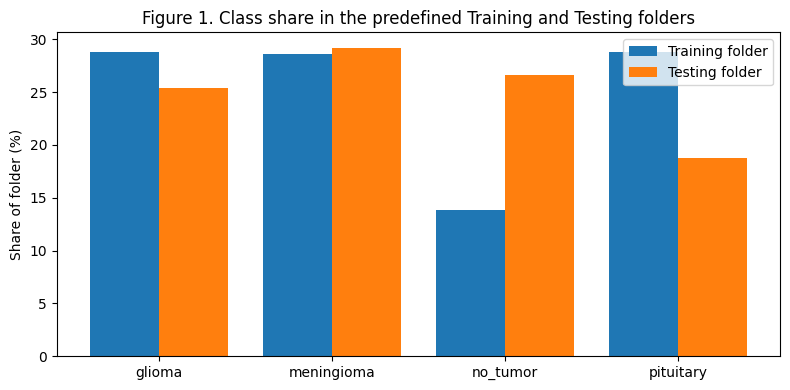

In [6]:
# Class distribution per folder (counts and percentages)
counts = pd.crosstab(df["class"], df["folder"])[["Training", "Testing"]].reindex(SHORT_NAMES)
counts["Total"] = counts.sum(axis=1)
# Share of each class within each folder
pct = (counts[["Training", "Testing"]] / counts[["Training", "Testing"]].sum() * 100).round(1)
# Counts and shares in one table
class_table = pd.concat([counts, pct.add_suffix(" %")], axis=1)
class_table.loc["Total"] = list(counts.sum()) + [100.0, 100.0]
class_table = class_table.astype({"Training": int, "Testing": int, "Total": int})
display(class_table)

# Figure 1: class shares per folder
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(SHORT_NAMES))
ax.bar(x - 0.2, pct["Training"], width=0.4, label="Training folder")
ax.bar(x + 0.2, pct["Testing"], width=0.4, label="Testing folder")
ax.set_xticks(x)
ax.set_xticklabels(SHORT_NAMES)
ax.set_ylabel("Share of folder (%)")
ax.set_title("Figure 1. Class share in the predefined Training and Testing folders")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_class_share.png", dpi=150)
plt.show()

Distinct native sizes : 440
Share at 512x512      : 71.7% (2,341 images)
Aspect ratio (w/h)    : min 0.64, median 1.00, max 1.78

Color modes:


,images
mode,
RGB,3264


Ten most common sizes:


,images
size,
512x512,2341
236x236,79
225x225,43
442x442,22
256x256,18
630x630,14
201x251,10
350x350,10
236x251,8


Share of 512x512 images by class:


,share_512x512
class,
glioma,0.911
meningioma,0.725
no_tumor,0.010
pituitary,0.902


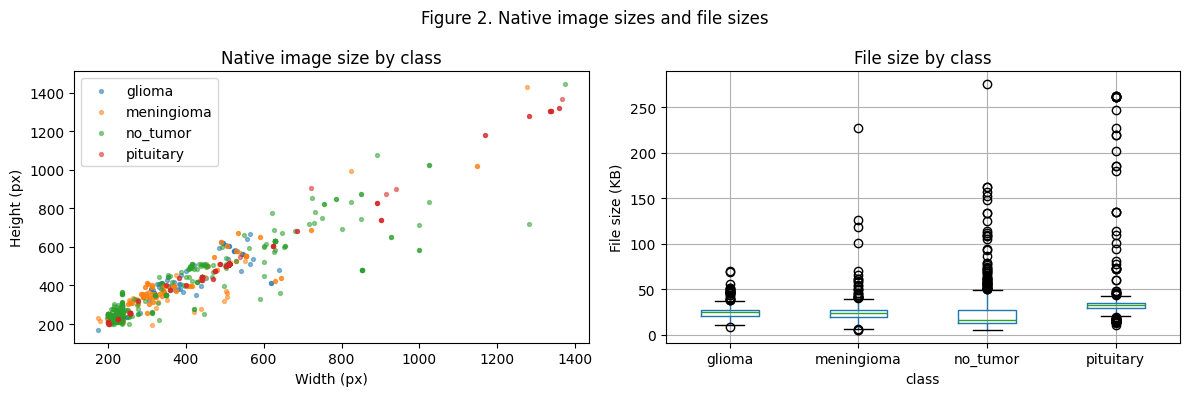

In [7]:
# Image size, color mode, and file size survey
df["size"] = df["width"].astype(str) + "x" + df["height"].astype(str)
df["aspect"] = df["width"] / df["height"]
# Summary of native sizes
print(f"Distinct native sizes : {df['size'].nunique()}")
print(f"Share at 512x512      : {(df['size'] == '512x512').mean():.1%} ({(df['size'] == '512x512').sum():,} images)")
print(f"Aspect ratio (w/h)    : min {df['aspect'].min():.2f}, median {df['aspect'].median():.2f}, max {df['aspect'].max():.2f}")
print("\nColor modes:")
display(df["mode"].value_counts().to_frame("images"))
print("Ten most common sizes:")
display(df["size"].value_counts().head(10).to_frame("images"))
print("Share of 512x512 images by class:")
display(df.assign(is_512=df["size"] == "512x512").groupby("class")["is_512"].mean().round(3).to_frame("share_512x512"))

# Figure 2: size scatter and file-size box plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls in SHORT_NAMES:
    sub = df[df["class"] == cls]
    axes[0].scatter(sub["width"], sub["height"], s=8, alpha=0.5, label=cls)
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Height (px)")
axes[0].set_title("Native image size by class")
axes[0].legend()
df.boxplot(column="file_kb", by="class", ax=axes[1])
axes[1].set_ylabel("File size (KB)")
axes[1].set_title("File size by class")
plt.suptitle("Figure 2. Native image sizes and file sizes")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_image_sizes.png", dpi=150)
plt.show()

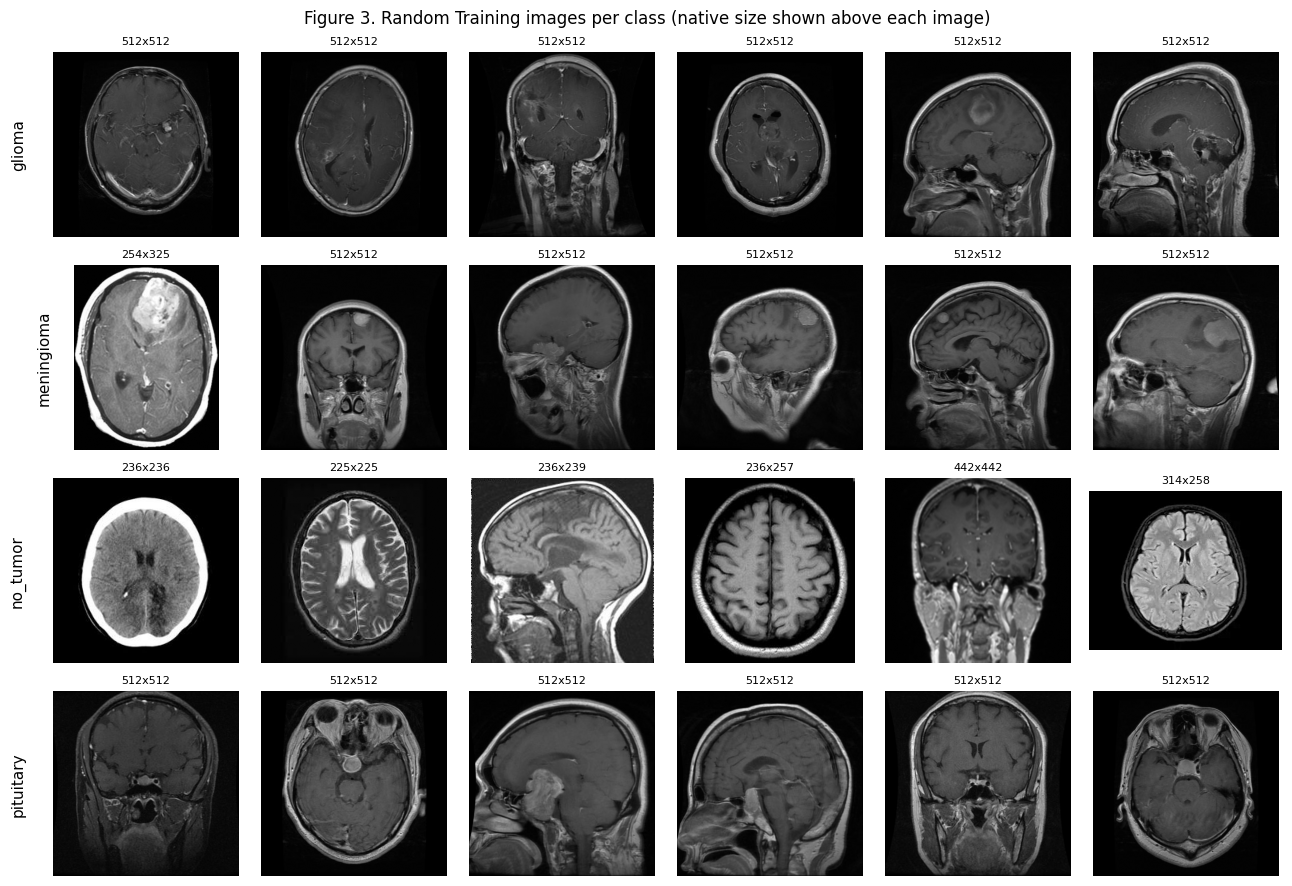

In [8]:
# Sample grid: six random Training images per class.
# Native images, before preprocessing.
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(13, 9))
# One row per class, six random images per row
for r, cls in enumerate(CLASSES):
    pool = df.index[(df.folder == "Training") & (df.label_name == cls)].to_numpy()
    for c, i in enumerate(rng.choice(pool, size=6, replace=False)):
        with Image.open(DATASET_ROOT / df.at[i, "path"]) as im:
            axes[r, c].imshow(im.convert("L"), cmap="gray")
        axes[r, c].set_title(f"{df.at[i, 'size']}", fontsize=8)
        axes[r, c].axis("off")
    # Class name to the left of each row
    axes[r, 0].text(-0.15, 0.5, SHORT[cls], transform=axes[r, 0].transAxes,
                    rotation=90, va="center", ha="right", fontsize=11)
plt.suptitle("Figure 3. Random Training images per class (native size shown above each image)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_sample_grid.png", dpi=150)
plt.show()

### Exploratory Findings

- **Class imbalance and folder shift (Figure 1).** No tumor is the smallest class: 395 of 2,870 Training images (13.8%) against about 29% for each tumor class. Its share almost doubles in the Testing folder (26.6%), while pituitary drops from 28.8% to 18.8%. This is why we use class weights, macro recall, and a stratified split.
- **Image formats.** The images come in **440 different native sizes**, and 71.7% are 512 × 512. This share is very different by class: 91.1% of gliomas, 90.2% of pituitary tumors, and 72.5% of meningiomas are 512 × 512, but only **1.0% of no-tumor images** are. Every file is stored as RGB even though the content is grayscale. Figure 2 shows that no-tumor images are spread over many smaller sizes and have a wider spread of file sizes.
- **Appearance (Figure 3).** The tumor images look like one consistent acquisition style: mostly T1 contrast-enhanced slices in axial, coronal, and sagittal planes. The no-tumor images look like a mix of other sources: T2-like and FLAIR-like contrasts, tighter crops, and even one CT-like scan.
- **What this means.** Image size and look are linked to the label, mainly for no tumor. A model could learn "this does not look like the usual 512 × 512 scan, so it is no tumor" instead of looking for a lesion. Our preprocessing removes size differences (crop, pad, resize to 64 × 64), but it cannot remove contrast or source differences. We test this risk directly in Section 7.3 (shortcut check).

## 5.3 Preprocessing

Every image goes through the same deterministic steps:

1. **Grayscale.** MRI intensity is single-channel. Every file is stored as RGB, so all are converted to one channel.
2. **Empty-border crop.** The bounding box of pixels brighter than 10 (out of 255) is kept, plus a 2-pixel margin. This removes black borders that differ between files and carry no diagnostic information.
3. **Square padding.** The crop is padded with zeros to a square, so resizing does not stretch the anatomy.
4. **Resize.** Bilinear resize to 64 × 64 for the MLP. This gives 4,096 inputs and keeps the first dense layer manageable. Stage 3 will use 224 × 224.
5. **Normalization.** Pixels are scaled to 0 to 1, then standardized with the mean and standard deviation of the **training split only** (Section 5.5). Validation and test data reuse the training statistics, so no information flows from them into training.

Steps 1 to 4 do not learn anything from the data, so they are safe to apply to all images before the split. Step 5 learns statistics, so it is computed after the split. No augmentation is used for the MLP baseline; augmentation is planned for the CNN in Stage 3.

Loaded cached 64x64 images: (3264, 64, 64)


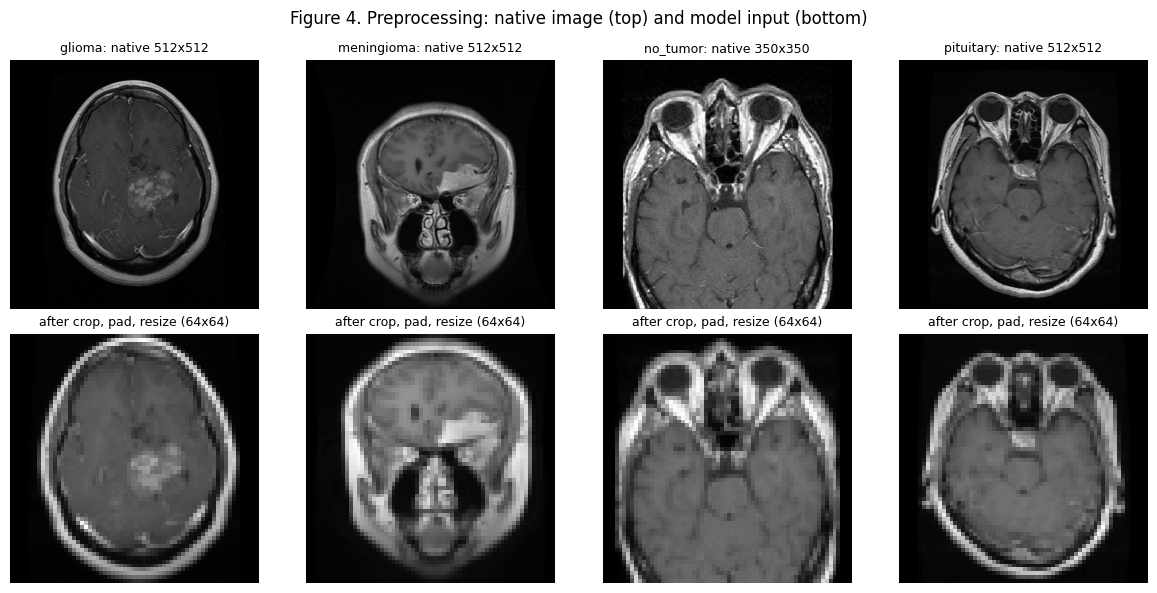

In [9]:
def load_and_preprocess(rel_path, size, thr=DATA_CFG["crop_threshold"], margin=DATA_CFG["crop_margin"]):
    # Grayscale -> crop border -> pad to square -> resize.
    # Returns a uint8 array of shape (size, size).
    with Image.open(DATASET_ROOT / rel_path) as im:
        g = np.asarray(im.convert("L"), dtype=np.uint8)
    # Pixels above the threshold belong to the head
    mask = g > thr
    if mask.sum() > 0.01 * mask.size:                 # skip the crop for almost-empty images
        # Bounding box of the head plus a small margin
        rows = np.where(mask.any(axis=1))[0]
        cols = np.where(mask.any(axis=0))[0]
        r0, r1 = max(rows[0] - margin, 0), min(rows[-1] + margin + 1, g.shape[0])
        c0, c1 = max(cols[0] - margin, 0), min(cols[-1] + margin + 1, g.shape[1])
        g = g[r0:r1, c0:c1]
    # Pad with zeros to a centered square
    h, w = g.shape
    side = max(h, w)
    canvas = np.zeros((side, side), dtype=np.uint8)
    top, left = (side - h) // 2, (side - w) // 2
    canvas[top:top + h, left:left + w] = g
    # Bilinear resize to the target size
    return np.asarray(Image.fromarray(canvas).resize((size, size), RESAMPLE), dtype=np.uint8)


def build_image_cache(frame, size):
    # Preprocess all images once and cache them.
    # The cache is rebuilt if the file list changes.
    # The file hashes give the cache its name
    fingerprint = hashlib.md5("".join(frame["md5"]).encode()).hexdigest()
    cache_file = CACHE_DIR / f"images_{size}_{fingerprint[:12]}.npy"
    # Reuse the cache when it exists
    if cache_file.exists():
        arr = np.load(cache_file)
        print(f"Loaded cached {size}x{size} images: {arr.shape}")
        return arr
    start = time.time()
    arr = np.stack([load_and_preprocess(p, size) for p in frame["path"]])
    np.save(cache_file, arr)
    print(f"Preprocessed {len(arr):,} images to {size}x{size} in {time.time() - start:.1f}s")
    return arr


# All images at 64 x 64 (row order = df)
IMG64 = build_image_cache(df, DATA_CFG["img_size_mlp"])

# Before and after: one example per class
fig, axes = plt.subplots(2, len(CLASSES), figsize=(12, 6))
for c, cls in enumerate(CLASSES):
    i = df.index[(df.folder == "Training") & (df.label_name == cls)][0]
    with Image.open(DATASET_ROOT / df.at[i, "path"]) as im:
        axes[0, c].imshow(im.convert("L"), cmap="gray")
    axes[0, c].set_title(f"{SHORT[cls]}: native {df.at[i, 'size']}", fontsize=9)
    axes[1, c].imshow(IMG64[i], cmap="gray")
    axes[1, c].set_title("after crop, pad, resize (64x64)", fontsize=9)
    for a in axes[:, c]:
        a.axis("off")
plt.suptitle("Figure 4. Preprocessing: native image (top) and model input (bottom)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_preprocessing.png", dpi=150)
plt.show()

## 5.4 Duplicate, Near-Duplicate, and Related-Image Audit

The instructor's feedback asked us to finish all duplicate checks **before** finalizing the splits, and to look for visually related slices, because the dataset has no patient IDs. We use three levels of similarity:

| Level | Detection | How it is used |
|---|---|---|
| **Exact duplicate** | Identical MD5 hash of the file bytes | Keep one copy |
| **Near duplicate** | Perceptual hash (pHash) Hamming distance ≤ 4 of 64 bits | Treated as the same image (re-saved, re-scaled, or re-compressed copy); keep one copy |
| **Related image** | pHash distance ≤ a threshold chosen from a sweep (Section 5.4.3) | Kept, but grouped: a group never crosses the train, validation, or test split |

**How pHash works.** Each preprocessed image is reduced to 32 × 32, transformed with a 2D discrete cosine transform (DCT), and the 8 × 8 lowest-frequency coefficients are compared with their median. This gives a 64-bit fingerprint of the coarse structure of the image (Zauner, 2010). Two images that look alike have fingerprints that differ in only a few bits. pHash is computed on the preprocessed images, so border differences do not hide copies. Because the median splits the coefficients in half, every fingerprint has the same number of 1-bits, so distances between two fingerprints are always **even** (0, 2, 4, ...).

In [10]:
def phash64(img_u8):
    # 64-bit perceptual hash (pHash).
    # Resize to 32x32 -> 2D DCT -> keep 8x8 low frequencies.
    # Each bit: is the coefficient above the median?
    small = np.asarray(Image.fromarray(img_u8).resize((32, 32), RESAMPLE), dtype=np.float32)
    coeffs = dct(dct(small, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8].ravel()
    bits = coeffs > np.median(coeffs[1:])             # median without the DC term
    return np.packbits(bits).view(np.uint64)[0]


# Number of 1-bits in every possible byte
POPCOUNT8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def hamming_matrix(a, b, chunk=256):
    # Pairwise Hamming distances between two hash arrays.
    # Returned as uint8 to save memory.
    a = np.ascontiguousarray(a, dtype=np.uint64)
    b = np.ascontiguousarray(b, dtype=np.uint64)
    out = np.empty((len(a), len(b)), dtype=np.uint8)
    # Work in chunks to limit memory use
    for i in range(0, len(a), chunk):
        # XOR marks differing bits; popcount counts them
        x = np.bitwise_xor(a[i:i + chunk, None], b[None, :])
        out[i:i + chunk] = POPCOUNT8[x.view(np.uint8)].reshape(x.shape[0], x.shape[1], 8).sum(axis=-1)
    return out


# Hash every preprocessed image
PHASH = np.array([phash64(img) for img in IMG64], dtype=np.uint64)
# DIST[i, j] = pHash distance between images i and j
DIST = hamming_matrix(PHASH, PHASH)
print(f"Distance matrix: {DIST.shape}, computed for {len(PHASH):,} images")

Distance matrix: (3264, 3264), computed for 3,264 images


### 5.4.1 Exact Duplicates

In [11]:
# Files whose MD5 hash appears more than once
dup_rows = df[df.duplicated("md5", keep=False)]
# One row per group of identical files
exact_groups = dup_rows.groupby("md5").agg(
    n_files=("path", "size"),
    folders=("folder", lambda s: "+".join(sorted(set(s)))),
    n_labels=("label", "nunique"),
)
# Summary counts of the exact-duplicate audit
exact_summary = pd.Series({
    "files in exact-duplicate groups": len(dup_rows),
    "exact-duplicate groups": len(exact_groups),
    "redundant copies (files minus groups)": len(dup_rows) - len(exact_groups),
    "groups inside Training only": int((exact_groups.folders == "Training").sum()),
    "groups inside Testing only": int((exact_groups.folders == "Testing").sum()),
    "groups shared by Training and Testing": int((exact_groups.folders == "Testing+Training").sum()),
    "groups with conflicting labels": int((exact_groups.n_labels > 1).sum()),
}, name="count")
display(exact_summary.to_frame())
# Extra copies (all but one per group)
print("Redundant exact copies per class and folder:")
display(dup_rows[dup_rows.duplicated("md5")].groupby(["folder", "class"]).size().unstack(fill_value=0))

,count
files in exact-duplicate groups,403
exact-duplicate groups,166
redundant copies (files minus groups),237
groups inside Training only,61
groups inside Testing only,41
groups shared by Training and Testing,64
groups with conflicting labels,0


Redundant exact copies per class and folder:


class,glioma,meningioma,no_tumor,pituitary
folder,,,,
Testing,16,2,88,38
Training,8,8,60,17


### 5.4.2 Near Duplicates

,count
near-duplicate clusters (size > 1),450
images in those clusters,1165
clusters with re-encoded copies (not byte-identical),337
clusters spanning Training and Testing,195
clusters with conflicting labels,5
largest cluster size,19


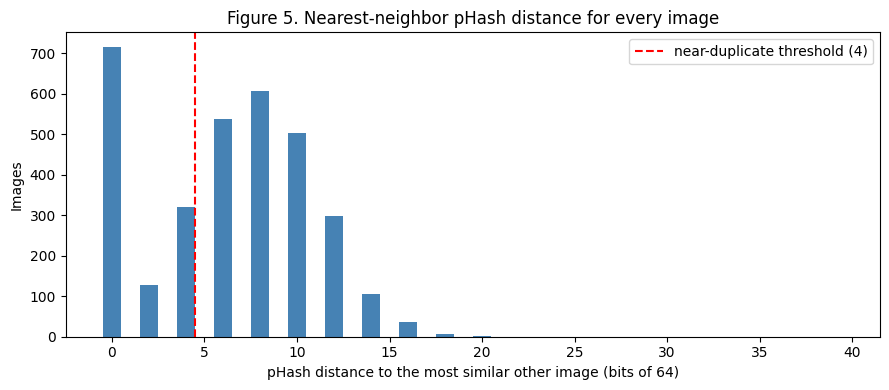

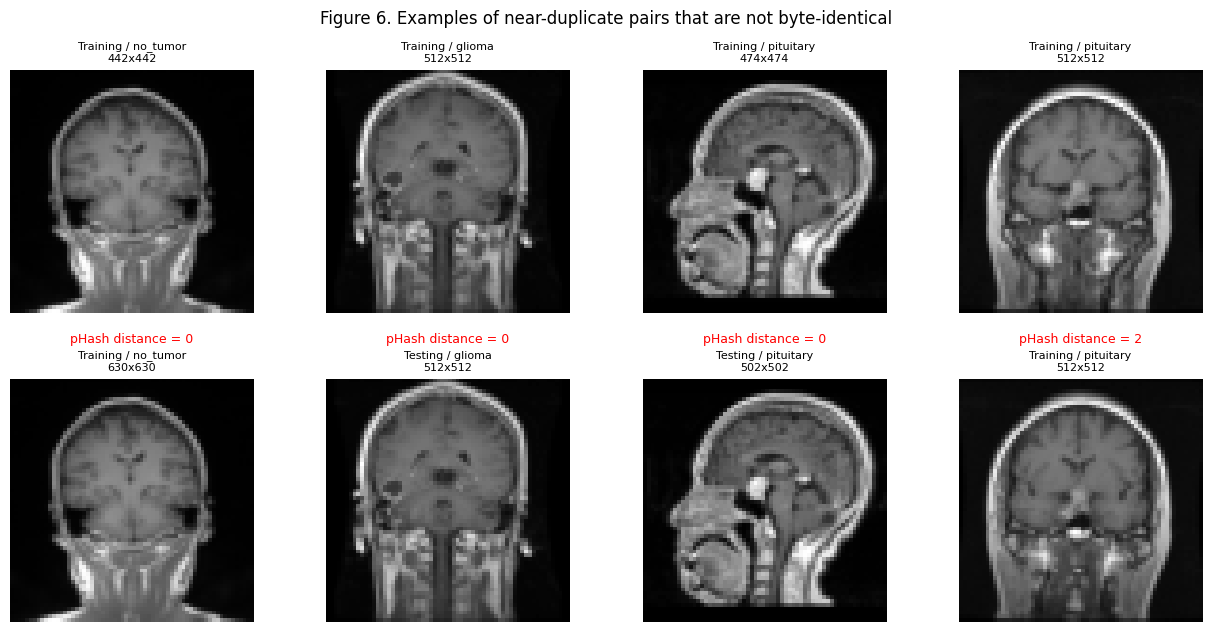

In [12]:
# Link images within NEAR_T bits.
# Each connected group is a near-duplicate cluster.
NEAR_T = DATA_CFG["near_dup_hamming"]
n_near_clusters, near_cluster = connected_components(csr_matrix(DIST <= NEAR_T), directed=False)
df["near_cluster"] = near_cluster

# Size, folders, labels, and distinct files per cluster
cluster_stats = df.groupby("near_cluster").agg(
    n=("path", "size"), n_folders=("folder", "nunique"),
    n_labels=("label", "nunique"), n_md5=("md5", "nunique"),
)
# Only clusters with two or more images
multi = cluster_stats[cluster_stats.n > 1]
near_summary = pd.Series({
    "near-duplicate clusters (size > 1)": len(multi),
    "images in those clusters": int(multi.n.sum()),
    "clusters with re-encoded copies (not byte-identical)": int((multi.n_md5 > 1).sum()),
    "clusters spanning Training and Testing": int((multi.n_folders > 1).sum()),
    "clusters with conflicting labels": int((multi.n_labels > 1).sum()),
    "largest cluster size": int(multi.n.max()) if len(multi) else 1,
}, name="count")
display(near_summary.to_frame())

# Distance from each image to its most similar other image
dist_no_self = DIST.copy()
# Ignore the distance of an image to itself
np.fill_diagonal(dist_no_self, 255)
nearest = dist_no_self.min(axis=1)
del dist_no_self

# Figure 5: nearest-neighbor distance histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(nearest, bins=np.arange(0, 41) - 0.5, color="steelblue")
ax.axvline(NEAR_T + 0.5, color="red", ls="--", label=f"near-duplicate threshold ({NEAR_T})")
ax.set_xlabel("pHash distance to the most similar other image (bits of 64)")
ax.set_ylabel("Images")
ax.set_title("Figure 5. Nearest-neighbor pHash distance for every image")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig05_nearest_distance.png", dpi=150)
plt.show()

# Show near-duplicate pairs that are not byte-identical.
# This checks the threshold visually.
pairs = np.argwhere(np.triu(DIST <= NEAR_T, k=1))
pairs = [(i, j) for i, j in pairs if df.at[i, "md5"] != df.at[j, "md5"]]
if pairs:
    # Four random pairs, reproducible with SEED
    pick = [pairs[k] for k in np.random.default_rng(SEED).choice(len(pairs), size=min(4, len(pairs)), replace=False)]
    fig, axes = plt.subplots(2, len(pick), figsize=(3.2 * len(pick), 6.4), squeeze=False)
    for c, (i, j) in enumerate(pick):
        for r, k in enumerate((i, j)):
            axes[r, c].imshow(IMG64[k], cmap="gray")
            axes[r, c].set_title(f"{df.at[k, 'folder']} / {df.at[k, 'class']}\n{df.at[k, 'size']}", fontsize=8)
            axes[r, c].axis("off")
        axes[0, c].text(0.5, -0.08, f"pHash distance = {DIST[i, j]}", transform=axes[0, c].transAxes,
                        ha="center", va="top", fontsize=9, color="red")
    plt.suptitle("Figure 6. Examples of near-duplicate pairs that are not byte-identical")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig06_near_duplicate_examples.png", dpi=150)
    plt.show()
else:
    print("No near-duplicate pairs beyond exact copies were found.")

### 5.4.3 Cleaning Rules and Related-Image Groups

First, we measure how much of the predefined Testing folder repeats the Training folder. Then we apply the rules below in order, before any split:

1. **Label conflicts.** If a near-duplicate cluster contains more than one label, the same image carries two diagnoses. We cannot tell which label is right, so **all** images in that cluster are removed.
2. **Redundant copies.** One image per near-duplicate cluster is kept across **both** folders (highest native resolution first, Training copy preferred on ties). This removes every exact and near copy, including Testing copies of Training images.
3. **Related-image groups.** Among the remaining images, images within the "related" distance are linked into groups (connected components). The threshold is chosen by a sweep: we take the **largest** candidate threshold whose largest group holds at most 2% of the pool. A threshold that is too high would chain unrelated scans into one giant group and make a stratified split impossible.

These rules only use file hashes and image fingerprints, never model predictions, so they do not bias the evaluation.

**Why the predefined Testing folder is not used as the test set (decided before any model saw test data).** Our first run applied the original plan: clean the Training folder and keep the cleaned Testing folder as the test set. The audit showed that **264 of the 394 Testing images (67%) are exact or near copies of Training images**, including **all 105 no-tumor Testing images** and 109 of the 115 meningiomas. After cleaning, only 87 Testing images would remain, with **zero no-tumor images** and only 6 meningiomas. A test set without one of the four classes cannot measure macro recall or no-tumor specificity. We therefore pool all cleaned images from both folders and build a new **group-aware train, validation, and test split** from that pool (Section 5.5). No model had been evaluated on any test image when this decision was made, so the change does not bias the final evaluation.

Testing images that are exact or near copies of a Training image: 264 of 394 (67.0%)


,Testing images,copies of a Training image,share copied
class,,,
glioma,100,23,0.230
meningioma,115,109,0.948
no_tumor,105,105,1.000
pituitary,74,27,0.365



Cleaned pool: 2,544 images; largest allowed group: 50 images


,groups,largest group,images in groups of 2+,share in groups of 2+,mixed-label groups,within size limit
threshold,,,,,,
6,2199,10,589,0.232,14,True
8,1604,120,1291,0.507,59,False
10,801,1441,1900,0.747,23,False


Selected related-image threshold: 6 bits


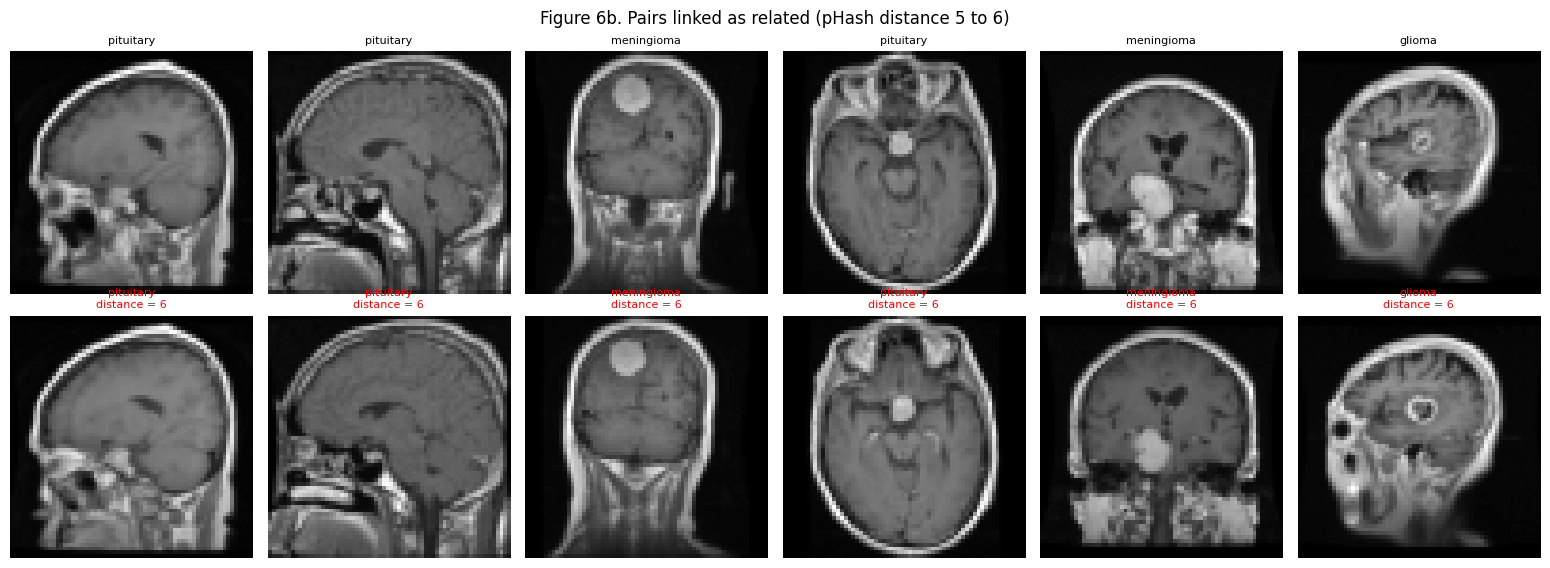


Images removed by rule:


folder,Testing,Training,All
drop_reason,,,
label conflict,10,26,36
redundant duplicate,297,387,684
All,307,413,720


Images per class before and after cleaning (Pool = cleaned images from both folders):


Raw            Clean              
folder     Training Testing Training Testing  Pool
class                                             
glioma          826     100      754      63   817
meningioma      822     115      743       6   749
no_tumor        395     105      298       0   298
pituitary       827      74      662      18   680
Total          2870     394     2457      87  2544

In [13]:
# Empty drop_reason = image is kept
df["drop_reason"] = ""

# Diagnostic: how much of the Testing folder
# repeats the Training folder?
clusters_with_training = set(df.loc[df.folder == "Training", "near_cluster"])
is_testing = df.folder == "Testing"
test_copy = is_testing & df.near_cluster.isin(clusters_with_training)
TESTING_COPIES = int(test_copy.sum())
print(f"Testing images that are exact or near copies of a Training image: "
      f"{TESTING_COPIES} of {int(is_testing.sum())} ({TESTING_COPIES / is_testing.sum():.1%})")
# Copies per class in the Testing folder
testing_copy_table = pd.DataFrame({
    "Testing images": df[is_testing].groupby("class").size(),
    "copies of a Training image": df[test_copy].groupby("class").size(),
}).reindex(SHORT_NAMES).fillna(0).astype(int)
testing_copy_table["share copied"] = (testing_copy_table.iloc[:, 1] / testing_copy_table.iloc[:, 0]).round(3)
display(testing_copy_table)

# Rule 1: label conflicts inside a near-duplicate cluster
conflict_clusters = cluster_stats.index[cluster_stats.n_labels > 1]
df.loc[df.near_cluster.isin(conflict_clusters), "drop_reason"] = "label conflict"

# Rule 2: keep one image per near-duplicate cluster.
# A cluster can span both folders.
remaining = df[df.drop_reason == ""].assign(pixels=lambda d: d.width * d.height,
                                            is_test=lambda d: d.folder == "Testing")
# Highest resolution first, then Training, then path
keepers = (remaining.sort_values(["pixels", "is_test", "path"], ascending=[False, True, True])
           .groupby("near_cluster").head(1).index)
df.loc[remaining.index.difference(keepers), "drop_reason"] = "redundant duplicate"

# Rule 3: sweep thresholds for related-image groups
# in the cleaned pool (both folders).
pool_idx = df.index[df.drop_reason == ""].to_numpy()
dist_pool = DIST[np.ix_(pool_idx, pool_idx)]
# Largest allowed group: 2% of the pool
max_group = max(2, int(DATA_CFG["max_group_fraction"] * len(pool_idx)))
sweep_rows = []
for t in DATA_CFG["related_hamming_candidates"]:
    # Group images linked at this threshold
    n_groups, comp = connected_components(csr_matrix(dist_pool <= t), directed=False)
    sizes = np.bincount(comp)
    labels_per_group = pd.Series(df.loc[pool_idx, "label"].to_numpy()).groupby(comp).nunique()
    sweep_rows.append({
        "threshold": t, "groups": n_groups, "largest group": int(sizes.max()),
        "images in groups of 2+": int(sizes[sizes > 1].sum()),
        "share in groups of 2+": round(float(sizes[sizes > 1].sum() / len(pool_idx)), 3),
        "mixed-label groups": int((labels_per_group > 1).sum()),
        "within size limit": bool(sizes.max() <= max_group),
    })
sweep_df = pd.DataFrame(sweep_rows).set_index("threshold")
# Largest threshold within the size limit
ok = sweep_df[sweep_df["within size limit"]]
RELATED_T = int(ok.index.max()) if len(ok) else NEAR_T
print(f"\nCleaned pool: {len(pool_idx):,} images; largest allowed group: {max_group} images")
display(sweep_df)
print(f"Selected related-image threshold: {RELATED_T} bits")

# Visual check: related pairs that are not near duplicates.
# Their distance is NEAR_T + 1 to RELATED_T.
rel_pairs = np.argwhere(np.triu((dist_pool > NEAR_T) & (dist_pool <= RELATED_T), k=1))
if len(rel_pairs):
    pick = rel_pairs[np.random.default_rng(SEED).choice(len(rel_pairs), size=min(6, len(rel_pairs)), replace=False)]
    fig, axes = plt.subplots(2, len(pick), figsize=(2.6 * len(pick), 5.8), squeeze=False)
    for c, (a, b) in enumerate(pick):
        for r, k in enumerate((pool_idx[a], pool_idx[b])):
            axes[r, c].imshow(IMG64[k], cmap="gray")
            axes[r, c].axis("off")
        axes[0, c].set_title(f"{df.at[pool_idx[a], 'class']}", fontsize=8)
        axes[1, c].set_title(f"{df.at[pool_idx[b], 'class']}\ndistance = {dist_pool[a, b]}", fontsize=8, color="red")
    plt.suptitle(f"Figure 6b. Pairs linked as related (pHash distance {NEAR_T + 1} to {RELATED_T})")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig06b_related_examples.png", dpi=150)
    plt.show()

# Cleaning summary
removed = df[df.drop_reason != ""]
print("\nImages removed by rule:")
display(pd.crosstab(removed.drop_reason, removed.folder, margins=True))
# Class counts before and after cleaning
raw_counts = pd.crosstab(df["class"], df.folder)[["Training", "Testing"]]
clean_counts = pd.crosstab(df.loc[df.drop_reason == "", "class"], df.loc[df.drop_reason == "", "folder"])
clean_counts = clean_counts.reindex(index=SHORT_NAMES, columns=["Training", "Testing"], fill_value=0)
cleaning_table = pd.concat({"Raw": raw_counts, "Clean": clean_counts}, axis=1).reindex(SHORT_NAMES)
cleaning_table[("Clean", "Pool")] = cleaning_table[("Clean", "Training")] + cleaning_table[("Clean", "Testing")]
cleaning_table.loc["Total"] = cleaning_table.sum()
print("Images per class before and after cleaning (Pool = cleaned images from both folders):")
display(cleaning_table)

### Cleaning Findings

- **Exact duplicates.** 403 files (12% of the dataset) belong to 166 groups of byte-identical copies, which means 237 redundant copies. 64 of these groups are shared by the Training and Testing folders. Most redundant copies are no-tumor images (60 in Training and 88 in Testing). No exact group had conflicting labels.
- **Near duplicates.** The pHash audit found many more copies than MD5 alone: 450 clusters holding 1,165 images (36% of the dataset), 337 of them with re-encoded or rescaled copies that MD5 cannot see, and 195 spanning both folders. In Figure 5, about 700 images have another image at distance 0, a clear sign of copies. Note that pHash distances are always even, so the bars appear only at 0, 2, 4, and so on. Figure 6 confirms that pairs within 4 bits are the same scan saved at different sizes or compression levels (for example, 442 × 442 and 630 × 630 versions of one no-tumor image).
- **Label conflicts.** 5 near-duplicate clusters carried two different labels. We removed all 36 images in them (26 from Training, 10 from Testing).
- **Testing folder.** 264 of 394 Testing images (67%) copy a Training image: 23% of gliomas, 36.5% of pituitary tumors, 94.8% of meningiomas, and 100% of no-tumor images. Any result reported on the original Testing folder therefore mostly measures recognition of images already seen in training.
- **Related threshold.** In the sweep, 6 bits gives 2,199 groups with a largest group of 10 images. At 8 bits, a single group already holds 120 images (above the 50-image limit), and at 10 bits one group holds 1,441 images, which shows that higher thresholds chain unrelated scans together. The rule therefore selected **6 bits**. Figure 6b shows that pairs linked at 6 bits look like neighbouring slices of the same scan, which is exactly what grouping should catch. At this threshold, 23.2% of the pool is in groups of two or more.
- **Result.** 720 images were removed (36 label conflicts and 684 redundant copies). The cleaned pool has 2,544 images: 817 glioma, 749 meningioma, 298 no tumor, and 680 pituitary.
- **Remaining uncertainty.** pHash only compares coarse structure. Two slices of the same patient that look different (for example, different planes or contrasts) are not linked, so some patient overlap between splits is still possible.

## 5.5 Data Splitting

- **Group-aware three-way split.** The cleaned pool (both folders) is split with `StratifiedGroupKFold` (seed 42) in two steps. First, 1 of 7 folds becomes the **test set** (about 14%). Then, from the rest, 1 of 6 folds becomes the **validation set** (about 14% of the pool). The remaining images, about 71%, are the **training set**. *Stratified* keeps the class shares similar in all three parts; *group* means a related-image group is never divided between them (scikit-learn developers, n.d.).
- **Test.** **The test set is not used until the final submission.** Model selection, experiment comparisons, and diagnostics at the midterm use the validation set only. No test tensors are even created in this notebook version.
- **Why not k-fold cross-validation?** Each configuration is already trained with three seeds; five folds on top would multiply the cost by five, and Module 8 notes that a single well-designed validation split is standard practice in deep learning.

After the split, we check the **residual similarity**: the pHash distance from each validation image to its closest training image, and from each test image to its closest training or validation image.

Share of the cleaned pool: train 71.0%, validation 14.1%, test 14.9%


split,train,val,test,train %,val %,test %
class,,,,,,
glioma,586,118,113,32.4,33.0,29.8
meningioma,537,106,106,29.7,29.6,28.0
no_tumor,212,43,43,11.7,12.0,11.3
pituitary,472,91,117,26.1,25.4,30.9
Total,1807,358,379,100.0,100.0,100.0


Original Kaggle folder of the images in each split:


folder,Testing,Training
split,,
train,64,1743
val,13,345
test,10,369


,validation vs train,test vs train + validation
images within 6 bits,0,0
images within 10 bits (borderline),229,245
median distance,10.0,10.0


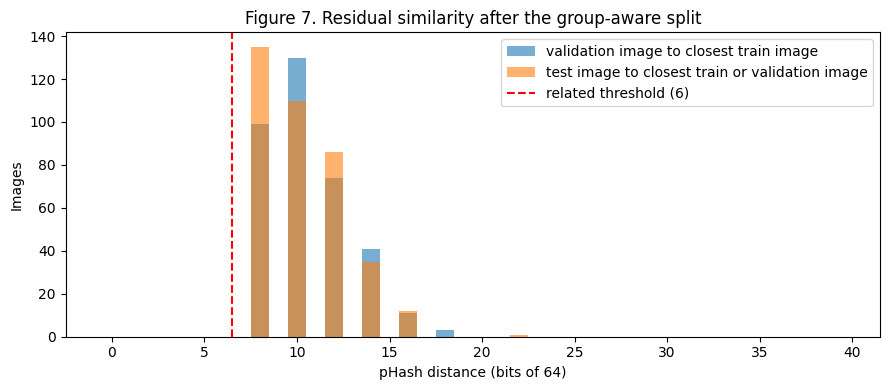

In [14]:
# Related-image groups at the selected threshold
pool = df.loc[pool_idx].copy()
_, related_group = connected_components(csr_matrix(dist_pool <= RELATED_T), directed=False)
pool["group"] = related_group

# Step 1: hold out the test set (1 of 7 group folds)
sgkf_test = StratifiedGroupKFold(n_splits=DATA_CFG["test_folds"], shuffle=True, random_state=SEED)
dev_pos, te_pos = next(sgkf_test.split(np.zeros(len(pool)), pool["label"], pool["group"]))
dev = pool.iloc[dev_pos]
test_idx = pool.index.to_numpy()[te_pos]

# Step 2: split the rest into train and validation
# (1 of 6 group folds).
sgkf_val = StratifiedGroupKFold(n_splits=DATA_CFG["val_folds"], shuffle=True, random_state=SEED)
tr_pos, va_pos = next(sgkf_val.split(np.zeros(len(dev)), dev["label"], dev["group"]))
train_idx = dev.index.to_numpy()[tr_pos]
val_idx = dev.index.to_numpy()[va_pos]

# Safety checks: no group crosses a split,
# and no image is lost.
groups_of = lambda idx: set(pool.loc[idx, "group"])
assert groups_of(train_idx).isdisjoint(groups_of(val_idx)), "a group crosses train/validation"
assert groups_of(train_idx).isdisjoint(groups_of(test_idx)), "a group crosses train/test"
assert groups_of(val_idx).isdisjoint(groups_of(test_idx)), "a group crosses validation/test"
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(pool_idx)

# Record each image's split and save the manifest
df["split"] = "removed"
df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"
df.loc[pool_idx, "related_group"] = pool["group"]
df[["path", "folder", "class", "md5", "near_cluster", "related_group", "drop_reason", "split"]].to_csv(
    RESULTS_DIR / "split_manifest.csv", index=False)

# Class counts and shares per split
kept = df[df.split != "removed"]
split_counts = pd.crosstab(kept["class"], kept["split"]).reindex(index=SHORT_NAMES, columns=["train", "val", "test"],
                                                                 fill_value=0)
split_pct = (split_counts / split_counts.sum() * 100).round(1)
split_table = pd.concat([split_counts, split_pct.add_suffix(" %")], axis=1)
split_table.loc["Total"] = list(split_counts.sum()) + [100.0, 100.0, 100.0]
split_table = split_table.astype({"train": int, "val": int, "test": int})
print(f"Share of the cleaned pool: train {len(train_idx) / len(pool_idx):.1%}, "
      f"validation {len(val_idx) / len(pool_idx):.1%}, test {len(test_idx) / len(pool_idx):.1%}")
display(split_table)
# Original Kaggle folder of each split
origin_table = pd.crosstab(kept["split"], kept["folder"]).reindex(index=["train", "val", "test"], fill_value=0)
print("Original Kaggle folder of the images in each split:")
display(origin_table)

# Residual similarity check
val_to_train = DIST[np.ix_(val_idx, train_idx)].min(axis=1)
dev_idx = np.concatenate([train_idx, val_idx])
test_to_dev = DIST[np.ix_(test_idx, dev_idx)].min(axis=1)
# Close pairs and median distance per split
residual = pd.DataFrame({
    "validation vs train": [int((val_to_train <= RELATED_T).sum()), int((val_to_train <= RELATED_T + 4).sum()),
                            float(np.median(val_to_train))],
    "test vs train + validation": [int((test_to_dev <= RELATED_T).sum()), int((test_to_dev <= RELATED_T + 4).sum()),
                                   float(np.median(test_to_dev))],
}, index=[f"images within {RELATED_T} bits", f"images within {RELATED_T + 4} bits (borderline)", "median distance"],
    dtype=object)
display(residual)

# Figure 7: residual distance histograms
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 41) - 0.5
ax.hist(val_to_train, bins=bins, alpha=0.6, label="validation image to closest train image")
ax.hist(test_to_dev, bins=bins, alpha=0.6, label="test image to closest train or validation image")
ax.axvline(RELATED_T + 0.5, color="red", ls="--", label=f"related threshold ({RELATED_T})")
ax.set_xlabel("pHash distance (bits of 64)")
ax.set_ylabel("Images")
ax.set_title("Figure 7. Residual similarity after the group-aware split")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig07_residual_similarity.png", dpi=150)
plt.show()

In [15]:
# Normalization statistics from the TRAINING split only.
# Then build tensors on the device.
TRAIN_MEAN = float(IMG64[train_idx].mean() / 255.0)
TRAIN_STD = float(IMG64[train_idx].std() / 255.0)
print(f"Training-split pixel mean = {TRAIN_MEAN:.4f}, std = {TRAIN_STD:.4f} (applied to every split)")


def to_tensor(indices, mean=TRAIN_MEAN, std=TRAIN_STD, images=None):
    # Standardize and add a channel axis
    images = IMG64 if images is None else images
    x = (images[indices].astype(np.float32) / 255.0 - mean) / std
    return torch.from_numpy(x).unsqueeze(1).to(DEVICE)          # shape (N, 1, H, W)


def make_data(tr, va, mean, std):
    # Tensors for training plus labels for metrics
    return {
        "X_train": to_tensor(tr, mean, std), "y_train": torch.as_tensor(df.loc[tr, "label"].to_numpy()).to(DEVICE),
        "X_val": to_tensor(va, mean, std), "y_val": torch.as_tensor(df.loc[va, "label"].to_numpy()).to(DEVICE),
        "y_val_np": df.loc[va, "label"].to_numpy(), "val_idx": va,
    }


DATA_CLEAN = make_data(train_idx, val_idx, TRAIN_MEAN, TRAIN_STD)
# Test tensors are deliberately NOT created here.
# The test set is reserved for the final submission.
print({k: tuple(v.shape) for k, v in DATA_CLEAN.items() if hasattr(v, "shape")})

Training-split pixel mean = 0.1998, std = 0.1752 (applied to every split)
{'X_train': (1807, 1, 64, 64), 'y_train': (1807,), 'X_val': (358, 1, 64, 64), 'y_val': (358,), 'y_val_np': (358,), 'val_idx': (358,)}


### Splitting Findings

- **Sizes.** Train 1,807 (71.0%), validation 358 (14.1%), and test 379 (14.9%) images. Because the cleaned Testing folder kept only 87 images, almost all images in every split come from the original Training folder (test: 369 from Training, 10 from Testing).
- **Class balance.** Stratification kept the shares close: no tumor is 11.7% of train, 12.0% of validation, and 11.3% of test. Groups must stay whole, so the match is not perfect (pituitary is 26.1% of train but 30.9% of test). This is the reason we report macro and per-class metrics.
- **Residual similarity (Figure 7).** By design, no validation or test image is within 6 bits of a training image. However, 229 of 358 validation images (64%) and 245 of 379 test images (65%) are within 10 bits, the borderline range, and the median distance is 10 for both. Some of these borderline pairs are probably related slices that the 6-bit rule could not link without creating giant groups. Our validation and test results are therefore still somewhat optimistic, but far less than with a random split (Experiment 3 measures how much less).
- **Why this is stricter than the proposal.** The Week 4 plan was a random stratified hold-out from Training with the Testing folder as the test set. The audit showed that this would have put copies and related slices on both sides of every split.

# 6. Stage 1: Foundational Modeling

## 6.1 Baseline Design and Justification

**Design rationale.** The baseline is a fully connected multilayer perceptron (MLP) on 64 × 64 grayscale images, flattened to 4,096 inputs. It is the simplest network that still contains the full deep learning pipeline (forward pass, loss, backpropagation, and gradient-based updates). Because it treats every pixel as an independent input, it has no built-in idea of spatial structure. That makes it a fair lower bound: any gain from the Stage 3 CNN can be linked to spatial inductive bias rather than to a better training recipe.

| Component | Choice | Justification |
|---|---|---|
| Input | 64 × 64 grayscale, flattened to 4,096 values | Small enough that the first dense layer stays manageable; still shows the overall shape of the head and any large lesion |
| Hidden layers | Dense 256 → Dense 128 | About 1.08M parameters, less than half the proposed 2.3M, as the feedback suggested for a small dataset (1,807 training images) |
| Activations | ReLU in hidden layers | Avoids the saturation and vanishing gradients of sigmoid and tanh (Module 4) |
| Initialization | He (Kaiming) normal for ReLU layers; Glorot (Xavier) normal for the output layer; biases at zero | Keeps activation variance stable through ReLU layers (He et al., 2015; Module 5) |
| Regularization | Dropout 0.25 after each hidden layer; early stopping | Dropout reduces co-adaptation of hidden units (Srivastava et al., 2014); 0.25 is a moderate start, and Experiment 1 tests 0 and 0.5 around it |
| Output | 4 raw logits (no softmax layer) | `nn.CrossEntropyLoss` applies log-softmax internally; softmax is applied only for probabilities in metrics and calibration |
| Loss | Weighted cross-entropy, inverse-frequency class weights from the training split | No tumor has about half the images of each tumor class; weights stop the model from ignoring it |
| Optimizer | Adam, learning rate 0.001 (implemented as `AdamW` with `weight_decay=0`) | Stable default for a first model (Kingma & Ba, 2015); AdamW lets Experiment 2 add decoupled weight decay without changing anything else (Loshchilov & Hutter, 2019) |

**Metrics.**

- **Primary:** validation **macro recall** (mean of the four per-class recalls). A missed tumor is worse than a false alarm, and macro averaging stops a model from scoring well by favoring the larger classes.
- **Secondary:** macro F1, accuracy, per-class precision, recall, and F1, and two binary clinical metrics that treat the three tumor classes as "tumor":
  - **Tumor detection sensitivity** = (tumor images predicted as any tumor class) / (all tumor images).
  - **Tumor false negative rate (FNR)** = (tumor images predicted as no tumor) / (all tumor images) = 1 − sensitivity, also reported **per tumor type**.
  - **No-tumor specificity** = (no-tumor images predicted as no tumor) / (all no-tumor images).
- **Calibration:** expected calibration error (ECE, 15 bins) of the top-class probability (Guo et al., 2017).
- **Generalization gap:** validation loss minus training loss at the best epoch. Both are measured in evaluation mode (dropout off), so they are directly comparable.

## 6.2 Training Configuration

| Setting | Value | Justification |
|---|---:|---|
| Epochs | Up to 50, early stopping with patience 8 on validation loss, best weights restored | 50 is enough for an MLP of this size to converge; patience 8 ignores short noisy plateaus while still stopping before long overfitting (Module 5) |
| Batch size | 32 | Common small batch; about 57 updates per epoch on our 1,807 training images, with useful gradient noise (Module 7) |
| Optimizer | Adam (AdamW, weight decay 0) | See Section 6.1 |
| Learning rate | 0.001 | Standard Adam default; learning-rate tuning was deferred to keep Stage 2 focused |
| Loss function | Weighted cross-entropy on logits | See Section 6.1 |
| Primary metric(s) | Validation macro recall; tumor FNR as the main clinical check | See Section 6.1 |
| Seeds | 42, 43, 44 | Mean ± standard deviation over three runs |

The data are small enough to keep on the GPU as tensors, so training is fast. The best weights of every run are saved to `checkpoints/` on Google Drive.

In [16]:
class MLP(nn.Module):
    # Fully connected baseline.
    # Flatten -> [Linear, ReLU, Dropout] x N -> Linear (logits)

    def __init__(self, in_features=DATA_CFG["img_size_mlp"] ** 2, hidden=(256, 128),
                 n_classes=len(CLASSES), dropout=0.25):
        super().__init__()
        # Build the layer stack
        layers, prev = [nn.Flatten()], in_features
        for width in hidden:
            layers += [nn.Linear(prev, width), nn.ReLU(), nn.Dropout(dropout)]
            prev = width
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
        self.reset_parameters()

    def reset_parameters(self):
        # Hidden layers first, output layer last
        linears = [m for m in self.net if isinstance(m, nn.Linear)]
        for m in linears[:-1]:
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")   # He initialization for ReLU layers
            nn.init.zeros_(m.bias)
        nn.init.xavier_normal_(linears[-1].weight)                    # Glorot initialization for the output layer
        nn.init.zeros_(linears[-1].bias)

    def forward(self, x):
        return self.net(x)                                            # raw logits, no softmax


def count_parameters(model):
    # Trainable weights and biases
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Build the baseline once to show its layers and size
baseline_preview = MLP(hidden=BASE_CFG["hidden"], dropout=BASE_CFG["dropout"])
print(baseline_preview)
print("\nTrainable parameters per layer:")
for name, p in baseline_preview.named_parameters():
    print(f"  {name:14s} {str(tuple(p.shape)):14s} {p.numel():>10,}")
print(f"  {'total':14s} {'':14s} {count_parameters(baseline_preview):>10,}")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.25, inplace=False)
    (7): Linear(in_features=128, out_features=4, bias=True)
  )
)

Trainable parameters per layer:
  net.1.weight   (256, 4096)     1,048,576
  net.1.bias     (256,)                256
  net.4.weight   (128, 256)         32,768
  net.4.bias     (128,)                128
  net.7.weight   (4, 128)              512
  net.7.bias     (4,)                    4
  total                          1,082,244


In [17]:
def class_weights(y):
    # Inverse-frequency weights: w_c = N / (K * n_c).
    # The average weight per training image is 1.
    counts = torch.bincount(y, minlength=len(CLASSES)).float()
    return (counts.sum() / (len(CLASSES) * counts)).to(DEVICE)


@torch.no_grad()
def predict_logits(model, X, batch=512):
    # Logits in evaluation mode, in batches
    model.eval()
    return torch.cat([model(X[i:i + batch]) for i in range(0, len(X), batch)])


def macro_recall_np(y_true, y_pred):
    # Mean of the four per-class recalls
    return recall_score(y_true, y_pred, labels=list(range(len(CLASSES))), average="macro", zero_division=0)


def expected_calibration_error(y_true, probs, n_bins=15):
    # Gap between confidence and accuracy per bin,
    # weighted by the share of images in the bin
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    correct = pred == y_true
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            ece += in_bin.mean() * abs(correct[in_bin].mean() - conf[in_bin].mean())
    return float(ece)


def safe_mean(x):
    # NaN instead of an error for empty arrays
    return float(np.mean(x)) if len(x) else float("nan")


def compute_metrics(y_true, probs):
    # All validation metrics from the probabilities
    pred = probs.argmax(axis=1)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, pred, labels=list(range(len(CLASSES))), zero_division=0)
    # Binary view: any tumor class vs no tumor
    tumor = y_true != NO_TUMOR
    m = {
        "macro_recall": float(rec.mean()),
        "macro_f1": float(f1.mean()),
        "accuracy": float((pred == y_true).mean()),
        "tumor_sensitivity": safe_mean(pred[tumor] != NO_TUMOR),
        "tumor_fnr": safe_mean(pred[tumor] == NO_TUMOR),
        "no_tumor_specificity": safe_mean(pred[~tumor] == NO_TUMOR),
        "ece": expected_calibration_error(y_true, probs),
    }
    # Per-class precision, recall, and F1
    for c in range(len(CLASSES)):
        m[f"precision_{SHORT_NAMES[c]}"] = float(prec[c])
        m[f"recall_{SHORT_NAMES[c]}"] = float(rec[c])
        m[f"f1_{SHORT_NAMES[c]}"] = float(f1[c])
    # Share of each tumor type predicted as no tumor
    for c in TUMOR_IDX:
        m[f"fnr_{SHORT_NAMES[c]}"] = safe_mean(pred[y_true == c] == NO_TUMOR)
    return m


def train_model(cfg, data, seed):
    # Train one MLP with early stopping on validation loss.
    # Returns the model with its best weights.
    set_seed(seed)
    model = MLP(hidden=cfg["hidden"], dropout=cfg["dropout"]).to(DEVICE)
    # Weighted cross-entropy on raw logits
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(data["y_train"]))
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    # Seeded generator for the mini-batch order
    generator = torch.Generator().manual_seed(seed)

    X_tr, y_tr, X_va, y_va = data["X_train"], data["y_train"], data["X_val"], data["y_val"]
    y_tr_np, y_va_np = y_tr.cpu().numpy(), y_va.cpu().numpy()
    n, bs = len(X_tr), cfg["batch_size"]
    # Per-epoch history and early-stopping state
    hist = {k: [] for k in ["train_loss", "val_loss", "train_macro_recall", "val_macro_recall", "train_loss_dropout"]}
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    start = time.time()

    for epoch in range(1, cfg["max_epochs"] + 1):
        # One pass over shuffled mini-batches (dropout on)
        model.train()
        perm = torch.randperm(n, generator=generator).to(DEVICE)
        running = 0.0
        for i in range(0, n, bs):
            batch = perm[i:i + bs]
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(X_tr[batch]), y_tr[batch])
            loss.backward()
            optimizer.step()
            running += loss.item() * len(batch)

        # Evaluation-mode passes (dropout off),
        # so train and validation numbers are comparable
        tr_logits, va_logits = predict_logits(model, X_tr), predict_logits(model, X_va)
        hist["train_loss"].append(loss_fn(tr_logits, y_tr).item())
        hist["val_loss"].append(loss_fn(va_logits, y_va).item())
        hist["train_macro_recall"].append(macro_recall_np(y_tr_np, tr_logits.argmax(1).cpu().numpy()))
        hist["val_macro_recall"].append(macro_recall_np(y_va_np, va_logits.argmax(1).cpu().numpy()))
        hist["train_loss_dropout"].append(running / n)

        # Keep the best weights; stop after `patience`
        # epochs without improvement
        if hist["val_loss"][-1] < best_loss - cfg["min_delta"]:
            best_loss, best_epoch, wait = hist["val_loss"][-1], epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break

    # Restore the best weights and summarize the run
    model.load_state_dict(best_state)
    hist["best_epoch"] = best_epoch
    info = {
        "best_epoch": best_epoch,
        "epochs_run": len(hist["val_loss"]),
        "train_loss_best": hist["train_loss"][best_epoch - 1],
        "val_loss_best": hist["val_loss"][best_epoch - 1],
        "gap": hist["val_loss"][best_epoch - 1] - hist["train_loss"][best_epoch - 1],
        "train_macro_recall_best": hist["train_macro_recall"][best_epoch - 1],
        "train_seconds": time.time() - start,
        "n_params": count_parameters(model),
    }
    return model, hist, info

In [18]:
RUNS = []        # one dict of metrics per (configuration, seed)
HISTORIES = {}   # (configuration, seed) -> training history
VAL_PROBS = {}   # (configuration, seed) -> validation probabilities
CONFIGS = {}     # configuration name -> full settings

# Metrics shown in the summary tables
KEY_METRICS = ["macro_recall", "macro_f1", "accuracy", "tumor_sensitivity", "tumor_fnr",
               "no_tumor_specificity", "ece", "gap", "best_epoch", "train_seconds"]


def run_config(name, overrides, data=None, seeds=SEEDS, extra_eval=None):
    # Train one configuration with every seed.
    # Evaluate on validation, save weights, log metrics.
    data = DATA_CLEAN if data is None else data
    cfg = {**BASE_CFG, **overrides}
    CONFIGS[name] = cfg
    RUNS[:] = [r for r in RUNS if r["config"] != name]        # rerunning a cell replaces old rows
    rows = []
    for seed in seeds:
        model, hist, info = train_model(cfg, data, seed)
        # Softmax only for metrics, not inside the model
        probs = torch.softmax(predict_logits(model, data["X_val"]), dim=1).cpu().numpy()
        metrics = compute_metrics(data["y_val_np"], probs)
        row = {"config": name, "seed": seed, "dropout": cfg["dropout"], "weight_decay": cfg["weight_decay"],
               **info, **metrics}
        # Optional extra metrics (used by Experiment 3)
        if extra_eval is not None:
            row.update(extra_eval(probs))
        rows.append(row)
        HISTORIES[(name, seed)] = hist
        VAL_PROBS[(name, seed)] = probs
        torch.save(model.state_dict(), CHECKPOINT_DIR / f"{name}_seed{seed}.pt")
        print(f"{name:22s} seed {seed}: best epoch {info['best_epoch']:2d}/{info['epochs_run']:2d} | "
              f"val macro recall {metrics['macro_recall']:.3f} | tumor FNR {metrics['tumor_fnr']:.3f} | "
              f"gap {info['gap']:+.3f} | {info['train_seconds']:.1f}s")
    RUNS.extend(rows)
    return pd.DataFrame(rows)


def summarize(names, metrics=KEY_METRICS):
    # Mean and std over seeds for each configuration.
    d = pd.DataFrame([r for r in RUNS if r["config"] in names])
    return d.groupby("config")[metrics].agg(["mean", "std"]).reindex(names)


def format_summary(agg, digits=3):
    # Turn a numeric summary into readable "mean ± std" strings.
    out = pd.DataFrame(index=agg.index)
    for metric in agg.columns.get_level_values(0).unique():
        # One decimal for epochs and seconds
        d = 1 if metric in ("best_epoch", "train_seconds") else digits
        out[metric] = [f"{m:.{d}f} ± {s:.{d}f}" for m, s in zip(agg[(metric, "mean")], agg[(metric, "std")])]
    return out


def select_best(agg, tol=0.01):
    # Highest mean validation macro recall wins.
    # Within `tol`, prefer the smaller generalization gap.
    top = agg[("macro_recall", "mean")].max()
    close = agg[agg[("macro_recall", "mean")] >= top - tol]
    return close[("gap", "mean")].idxmin()


def plot_learning_curves(name, title, fname, seeds=SEEDS):
    # Loss and macro recall per epoch, one color per seed
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for seed, color in zip(seeds, colors):
        h = HISTORIES[(name, seed)]
        ep = np.arange(1, len(h["val_loss"]) + 1)
        axes[0].plot(ep, h["train_loss"], color=color, label=f"train, seed {seed}")
        axes[0].plot(ep, h["val_loss"], color=color, ls="--", label=f"validation, seed {seed}")
        axes[1].plot(ep, h["train_macro_recall"], color=color, label=f"train, seed {seed}")
        axes[1].plot(ep, h["val_macro_recall"], color=color, ls="--", label=f"validation, seed {seed}")
        for a in axes:
            # Dotted line at the best epoch
            a.axvline(h["best_epoch"], color=color, ls=":", lw=1)
    axes[0].set_ylabel("Weighted cross-entropy (eval mode)")
    axes[1].set_ylabel("Macro recall")
    for a in axes:
        a.set_xlabel("Epoch")
        a.grid(alpha=0.3)
    axes[0].legend(fontsize=7, ncol=2)
    axes[0].set_title("Loss (dotted line = best epoch)")
    axes[1].set_title("Macro recall")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=150)
    plt.show()


def plot_experiment(names, labels, title, fname, seed=SEED):
    # Left: loss curves; middle and right: bars over seeds
    agg = summarize(names)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for name, label in zip(names, labels):
        h = HISTORIES[(name, seed)]
        ep = np.arange(1, len(h["val_loss"]) + 1)
        line, = axes[0].plot(ep, h["val_loss"], ls="--", label=f"{label} validation")
        axes[0].plot(ep, h["train_loss"], color=line.get_color(), alpha=0.6, label=f"{label} train")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Weighted cross-entropy (eval mode)")
    axes[0].set_title(f"Loss curves (seed {seed})")
    axes[0].legend(fontsize=7)
    x = np.arange(len(names))
    for ax, metric, ylabel in [(axes[1], "macro_recall", "Validation macro recall"),
                               (axes[2], "gap", "Generalization gap (val - train loss)")]:
        ax.bar(x, agg[(metric, "mean")], yerr=agg[(metric, "std")], capsize=5, color="steelblue")
        ax.set_xticks(x)
        ax.set_xticklabels(labels)
        ax.set_ylabel(ylabel)
        ax.set_title(f"{ylabel} (mean ± std, 3 seeds)", fontsize=10)
    # Zoom the recall axis on the useful range
    lo = agg[("macro_recall", "mean")].min() - 0.1
    axes[1].set_ylim(max(0.0, lo), 1.0)
    for a in axes:
        a.grid(alpha=0.3)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=150)
    plt.show()

## 6.3 Baseline Training

The baseline is trained three times (seeds 42, 43, 44) on the cleaned, group-aware training split and evaluated on the validation split.

In [19]:
# Baseline: BASE_CFG with no overrides, three seeds
baseline_runs = run_config("S1_baseline", {})
# Per-seed results
display(baseline_runs[["seed", "best_epoch", "epochs_run", "train_loss_best", "val_loss_best", "gap",
                       "train_macro_recall_best", "macro_recall", "macro_f1", "accuracy", "tumor_fnr"]].round(3))

S1_baseline            seed 42: best epoch  7/15 | val macro recall 0.717 | tumor FNR 0.098 | gap +0.252 | 3.0s
S1_baseline            seed 43: best epoch 17/25 | val macro recall 0.744 | tumor FNR 0.067 | gap +0.532 | 4.2s
S1_baseline            seed 44: best epoch 12/20 | val macro recall 0.738 | tumor FNR 0.121 | gap +0.423 | 3.4s


,seed,best_epoch,epochs_run,train_loss_best,val_loss_best,gap,train_macro_recall_best,macro_recall,macro_f1,accuracy,tumor_fnr
0,42,7,15,0.503,0.756,0.252,0.817,0.717,0.688,0.704,0.098
1,43,17,25,0.216,0.747,0.532,0.926,0.744,0.736,0.740,0.067
2,44,12,20,0.336,0.759,0.423,0.882,0.738,0.700,0.704,0.121


## 6.4 Baseline Results

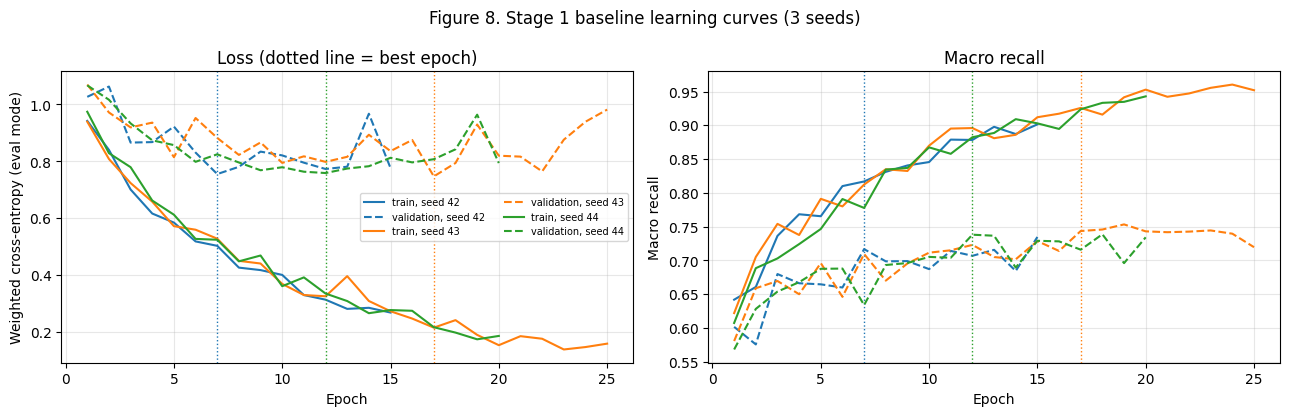

Baseline validation metrics (mean ± std over 3 seeds):


config,S1_baseline
macro_recall,0.733 ± 0.014
macro_f1,0.708 ± 0.025
accuracy,0.716 ± 0.021
tumor_sensitivity,0.905 ± 0.027
tumor_fnr,0.095 ± 0.027
no_tumor_specificity,0.798 ± 0.075
ece,0.081 ± 0.019
gap,0.402 ± 0.141
best_epoch,12.0 ± 5.0
train_seconds,3.5 ± 0.6


Baseline per-class validation metrics (mean ± std over 3 seeds):


,precision,recall,F1
glioma,0.780 ± 0.075,0.718 ± 0.072,0.743 ± 0.018
meningioma,0.669 ± 0.077,0.569 ± 0.133,0.604 ± 0.058
no_tumor,0.540 ± 0.056,0.798 ± 0.075,0.641 ± 0.025
pituitary,0.843 ± 0.043,0.846 ± 0.038,0.843 ± 0.007


In [20]:
# Figure 8: learning curves for all three seeds
plot_learning_curves("S1_baseline", "Figure 8. Stage 1 baseline learning curves (3 seeds)", "fig08_baseline_curves.png")

# Mean ± std of the key metrics
print("Baseline validation metrics (mean ± std over 3 seeds):")
display(format_summary(summarize(["S1_baseline"])).T)

# Per-class precision, recall, and F1 over seeds
per_class_cols = [f"{m}_{c}" for c in SHORT_NAMES for m in ("precision", "recall", "f1")]
base_rows = pd.DataFrame([r for r in RUNS if r["config"] == "S1_baseline"])
per_class = pd.DataFrame({
    c: [f"{base_rows[f'{m}_{c}'].mean():.3f} ± {base_rows[f'{m}_{c}'].std():.3f}" for m in ("precision", "recall", "f1")]
    for c in SHORT_NAMES}, index=["precision", "recall", "F1"]).T
print("Baseline per-class validation metrics (mean ± std over 3 seeds):")
display(per_class)

### Baseline Interpretation

- **Convergence and overfitting (Figure 8).** Training loss falls steadily from about 0.95 to about 0.15, but validation loss levels off at about 0.75 to 0.85 after 5 to 7 epochs and then becomes noisy, with spikes close to 1.0. Early stopping picked epochs 7, 17, and 12. At those epochs, training macro recall is 0.82 to 0.93 while validation macro recall is 0.72 to 0.74, and the loss gap is 0.402 ± 0.141. The MLP is not underfitting; it **overfits early**. It quickly memorizes training images instead of learning patterns that transfer.
- **Overall level and stability.** Validation macro recall is 0.733 ± 0.014 and macro F1 is 0.708 ± 0.025. The small standard deviation means the result is stable across seeds, so it is a reliable reference for Stage 2.
- **Per class.** Pituitary is the easiest class (recall 0.846, F1 0.843), probably because the tumor sits in a fixed location at the skull base. Glioma is moderate (recall 0.718). **Meningioma is clearly the hardest** (recall 0.569 ± 0.133, with a large spread across seeds). No tumor has a good recall (0.798) but a low precision (0.540), which means many tumor images are predicted as no tumor.
- **Clinical view.** Tumor detection sensitivity is 0.905 ± 0.027, so the tumor false negative rate is 0.095: about 1 in 10 tumor images is called "no tumor". Meningiomas make up the largest share of the missed tumors (Section 7.3).
- **What this says about the task, data, and model.** About 0.73 macro recall from 64 × 64 inputs shows that the task is learnable, but an MLP has a low ceiling. It has a separate weight for every pixel position, so a lesion that moves a few pixels looks like a new pattern, and it has no way to build local shape features. The size of the gap suggests that **overfitting** is the first weakness to target in Stage 2, and the per-class results suggest that **meningioma** is the class to watch.

# 7. Stage 2: Optimization and Diagnostic Analysis

## 7.1 Experimental Plan

The feedback asked us to prioritize. We chose experiments that target the main risk of the baseline, which is **overfitting** (about 1.08M weights for 1,807 training images), and the main risk of the **evaluation**, which is **leakage**.

| Experiment | Factor changed | Values | Question |
|---|---|---|---|
| 1 | Dropout probability | 0, **0.25 (baseline)**, 0.5 | Does dropout reduce overfitting and improve validation macro recall? |
| 2 | Weight decay (AdamW, decoupled) | **0**, 1e-2, 1e-1, at the best dropout from Exp 1 | Does an explicit penalty on weight size help further? |
| 3 | Data protocol | Naive random split of raw data vs our cleaned, group-aware split | How much does leakage inflate validation results? |

**Rules for every experiment:** one factor changes at a time; everything else (data split, preprocessing, architecture, initialization, learning rate, batch size, epoch budget, early stopping, class weights, and seeds) stays fixed; every configuration is trained with three seeds; and all comparisons use the **validation** set.

**Selection rule (fixed before running):** carry forward the configuration with the highest mean validation macro recall. If two configurations are within 0.01, pick the one with the smaller mean generalization gap, because it is more likely to hold up on new data.

Learning-rate, optimizer, scheduling, batch-size, and batch-normalization experiments were deferred. With early stopping and Adam, the baseline already trains stably, so these are lower priority than overfitting for an MLP at this data size.

### Experiment 1: Dropout Strength

**Question or hypothesis:** The baseline has far more weights than training images, so it should overfit quickly. Without dropout (p = 0), the train-validation gap should be wider and the best epoch earlier. Stronger dropout (p = 0.5) should narrow the gap and may slow convergence. We expect a moderate or strong dropout to give the best validation macro recall.  
**Variable changed:** dropout probability after each hidden layer: 0, 0.25 (baseline, reused from Section 6.3), 0.5.  
**Controls:** same split, preprocessing, architecture (256-128), initialization, AdamW with learning rate 0.001 and weight decay 0, batch size 32, up to 50 epochs with patience 8, class weights, and seeds 42, 43, 44.  
**Evaluation criteria:** mean ± std validation macro recall (primary), macro F1, tumor FNR, generalization gap at the best epoch, and best epoch.

E1_dropout_0.00        seed 42: best epoch  7/15 | val macro recall 0.690 | tumor FNR 0.051 | gap +0.532 | 2.3s
E1_dropout_0.00        seed 43: best epoch  8/16 | val macro recall 0.764 | tumor FNR 0.044 | gap +0.607 | 2.5s
E1_dropout_0.00        seed 44: best epoch 11/19 | val macro recall 0.737 | tumor FNR 0.060 | gap +0.636 | 3.1s
E1_dropout_0.50        seed 42: best epoch 18/26 | val macro recall 0.710 | tumor FNR 0.117 | gap +0.276 | 4.9s
E1_dropout_0.50        seed 43: best epoch 38/46 | val macro recall 0.688 | tumor FNR 0.051 | gap +0.347 | 7.9s
E1_dropout_0.50        seed 44: best epoch 31/39 | val macro recall 0.706 | tumor FNR 0.067 | gap +0.347 | 6.5s


,macro_recall,macro_f1,accuracy,tumor_sensitivity,tumor_fnr,no_tumor_specificity,ece,gap,best_epoch,train_seconds
p = 0,0.730 ± 0.038,0.726 ± 0.033,0.736 ± 0.026,0.948 ± 0.008,0.052 ± 0.008,0.659 ± 0.094,0.100 ± 0.015,0.591 ± 0.054,8.7 ± 2.1,2.6 ± 0.4
p = 0.25 (baseline),0.733 ± 0.014,0.708 ± 0.025,0.716 ± 0.021,0.905 ± 0.027,0.095 ± 0.027,0.798 ± 0.075,0.081 ± 0.019,0.402 ± 0.141,12.0 ± 5.0,3.5 ± 0.6
p = 0.5,0.702 ± 0.012,0.689 ± 0.013,0.694 ± 0.012,0.922 ± 0.035,0.078 ± 0.035,0.705 ± 0.075,0.073 ± 0.028,0.324 ± 0.041,29.0 ± 10.1,6.4 ± 1.5


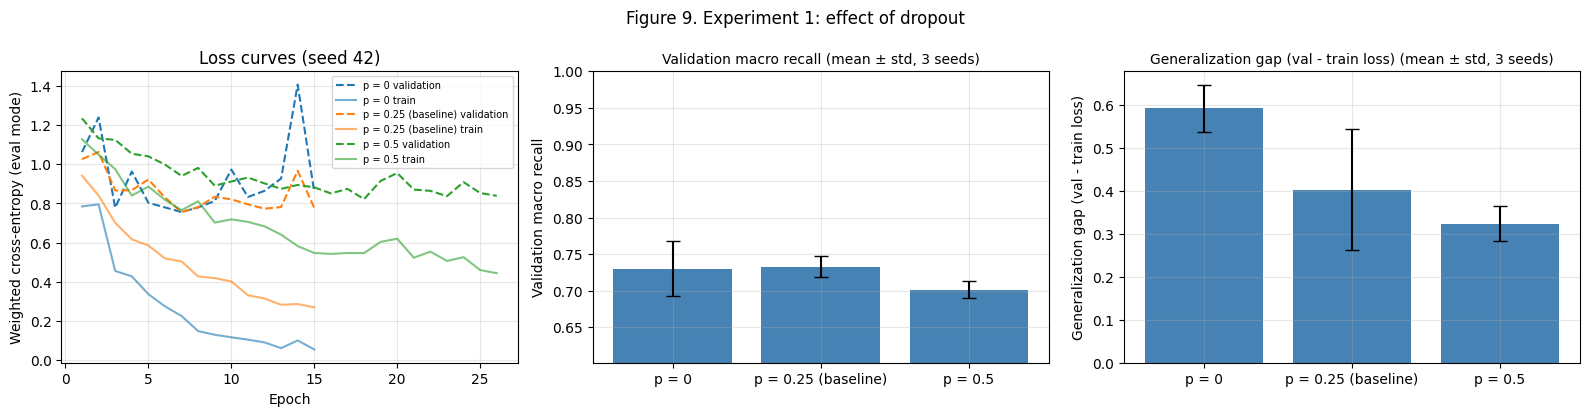

Selected by the rule: S1_baseline (dropout = 0.25)


In [21]:
# Experiment 1: dropout 0 and 0.5
# p = 0.25 is the baseline, reused from Section 6.3
E1_NAMES = ["E1_dropout_0.00", "S1_baseline", "E1_dropout_0.50"]
E1_LABELS = ["p = 0", "p = 0.25 (baseline)", "p = 0.5"]
# Only dropout changes; everything else is fixed
run_config("E1_dropout_0.00", {"dropout": 0.0})
run_config("E1_dropout_0.50", {"dropout": 0.5})

# Compare the three settings and plot them
e1_summary = summarize(E1_NAMES)
display(format_summary(e1_summary).set_axis(E1_LABELS))
plot_experiment(E1_NAMES, E1_LABELS, "Figure 9. Experiment 1: effect of dropout", "fig09_exp1_dropout.png")

# Selection rule fixed in Section 7.1
BEST_E1 = select_best(e1_summary)
BEST_DROPOUT = CONFIGS[BEST_E1]["dropout"]
print(f"Selected by the rule: {BEST_E1} (dropout = {BEST_DROPOUT})")

**Experiment 1 interpretation:** Dropout behaved as expected on the **gap**, but not on **validation performance**.

- **Gap.** The train-validation loss gap fell steadily as dropout increased: 0.591 ± 0.054 (p = 0), 0.402 ± 0.141 (p = 0.25), and 0.324 ± 0.041 (p = 0.5).
- **p = 0.** Without dropout, the model overfits fastest. The best epoch comes earliest (8.7 on average), training loss drops to about 0.05, and the seed 42 validation loss is unstable, with a spike to about 1.4 near epoch 14 (Figure 9, left). Its macro recall (0.730 ± 0.038) is close to the baseline but much less stable across seeds.
- **p = 0.5.** Strong dropout slows learning and starts to **underfit**. It needs 29 epochs on average, training loss stays high (about 0.45 at the end), and validation loss stays above the other two curves. Its macro recall is the lowest (0.702 ± 0.012), about two standard deviations below the baseline. Its smaller gap comes mostly from a higher training loss, not from a lower validation loss.
- **Why training loss can sit near or above validation loss with dropout:** during training, dropout switches off units, which makes the training task harder. We report losses in evaluation mode (dropout off), so our curves avoid this effect.
- **Decision.** The baseline (p = 0.25) has the highest mean macro recall (0.733). p = 0 is within the 0.01 tolerance, but its gap is larger, so the rule keeps **p = 0.25**. The differences between p = 0 and p = 0.25 are within the seed noise, so the main lesson is that moderate dropout gives the same accuracy with less overfitting and more stable runs, while strong dropout costs accuracy.

### Experiment 2: Weight Decay

**Question or hypothesis:** Dropout adds noise to the hidden units, while weight decay directly shrinks the weights. Adding decoupled weight decay on top of the best dropout should reduce the train-validation gap further. A value that is too large could start to underfit.  
**Why these values (changed from the proposal):** in PyTorch's `AdamW`, each step multiplies every weight by (1 − learning rate × weight decay). With a learning rate of 0.001, the proposal's values of 1e-4 and 1e-3 shrink the weights by only 1e-7 to 1e-6 per step, which is about 0.2% or less over a whole run. Our first run confirmed this: the loss curves for 1e-4 and 1e-3 overlapped the curve for 0, and validation macro recall did not change beyond the seed-to-seed noise. We therefore test **1e-2 and 1e-1**, the usual range for AdamW (Loshchilov & Hutter, 2019), which shrink the weights by about 1% and 10 to 14% over a typical run (about 1,000 to 1,500 update steps).  
**Variable changed:** AdamW weight decay: 0 (reused from the best Experiment 1 configuration), 1e-2, 1e-1.  
**Controls:** dropout fixed at the value selected in Experiment 1; everything else as in Experiment 1. `AdamW` decouples weight decay from the adaptive gradient scaling, so the loss we report is the pure cross-entropy, and the losses of all configurations stay comparable.  
**Evaluation criteria:** same as Experiment 1.

E2_p0.25_wd_1e-02      seed 42: best epoch 13/21 | val macro recall 0.737 | tumor FNR 0.083 | gap +0.424 | 3.7s
E2_p0.25_wd_1e-02      seed 43: best epoch 10/18 | val macro recall 0.713 | tumor FNR 0.073 | gap +0.388 | 3.2s
E2_p0.25_wd_1e-02      seed 44: best epoch 12/20 | val macro recall 0.717 | tumor FNR 0.086 | gap +0.389 | 3.4s
E2_p0.25_wd_1e-01      seed 42: best epoch 18/26 | val macro recall 0.731 | tumor FNR 0.067 | gap +0.519 | 4.6s
E2_p0.25_wd_1e-01      seed 43: best epoch 16/24 | val macro recall 0.742 | tumor FNR 0.057 | gap +0.549 | 4.1s
E2_p0.25_wd_1e-01      seed 44: best epoch 11/19 | val macro recall 0.688 | tumor FNR 0.073 | gap +0.384 | 3.2s


,macro_recall,macro_f1,accuracy,tumor_sensitivity,tumor_fnr,no_tumor_specificity,ece,gap,best_epoch,train_seconds
wd = 0,0.733 ± 0.014,0.708 ± 0.025,0.716 ± 0.021,0.905 ± 0.027,0.095 ± 0.027,0.798 ± 0.075,0.081 ± 0.019,0.402 ± 0.141,12.0 ± 5.0,3.5 ± 0.6
wd = 1e-02,0.722 ± 0.012,0.706 ± 0.006,0.716 ± 0.011,0.920 ± 0.007,0.080 ± 0.007,0.721 ± 0.070,0.085 ± 0.013,0.400 ± 0.020,11.7 ± 1.5,3.4 ± 0.3
wd = 1e-01,0.720 ± 0.028,0.712 ± 0.024,0.720 ± 0.021,0.934 ± 0.008,0.066 ± 0.008,0.682 ± 0.088,0.083 ± 0.023,0.484 ± 0.088,15.0 ± 3.6,4.0 ± 0.7


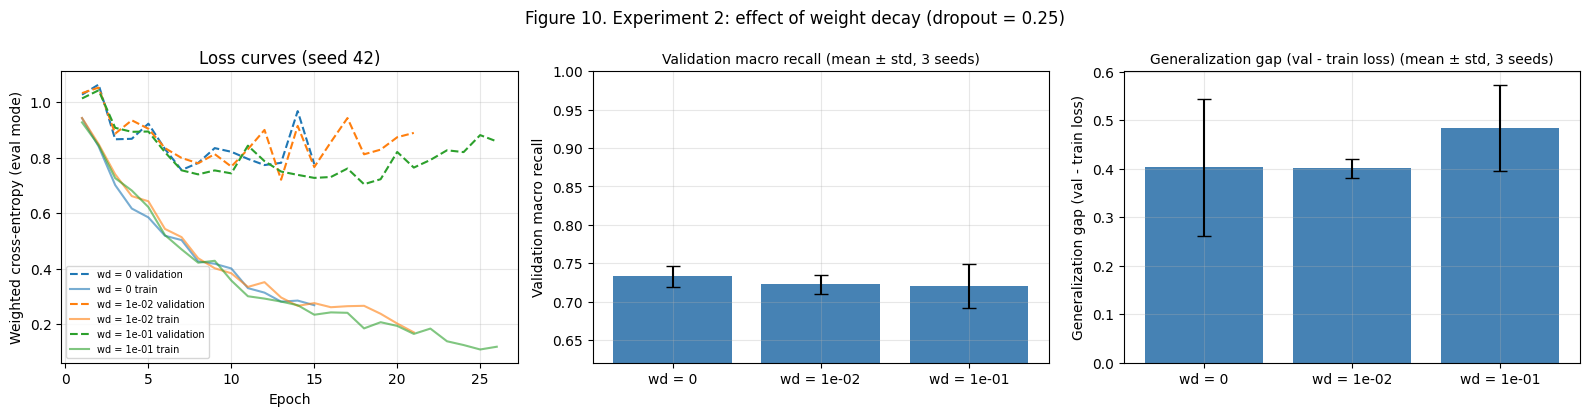

Selected configuration to carry forward: S1_baseline -> dropout = 0.25, weight decay = 0.0


In [22]:
# Experiment 2: weight decay on top of the best dropout
# wd = 0 is reused from Experiment 1
E2_NAMES = [BEST_E1]
E2_LABELS = ["wd = 0"]
for wd in [1e-2, 1e-1]:
    name = f"E2_p{BEST_DROPOUT:.2f}_wd_{wd:.0e}"
    run_config(name, {"dropout": BEST_DROPOUT, "weight_decay": wd})
    E2_NAMES.append(name)
    E2_LABELS.append(f"wd = {wd:.0e}")

# Compare the three settings and plot them
e2_summary = summarize(E2_NAMES)
display(format_summary(e2_summary).set_axis(E2_LABELS))
plot_experiment(E2_NAMES, E2_LABELS, f"Figure 10. Experiment 2: effect of weight decay (dropout = {BEST_DROPOUT})",
                "fig10_exp2_weight_decay.png")

# Configuration carried forward to Section 7.3
SELECTED = select_best(e2_summary)
print(f"Selected configuration to carry forward: {SELECTED} -> "
      f"dropout = {CONFIGS[SELECTED]['dropout']}, weight decay = {CONFIGS[SELECTED]['weight_decay']}")

**Experiment 2 interpretation:** Weight decay did **not** improve the model.

- **Macro recall.** 0.733 ± 0.014 (wd = 0), 0.722 ± 0.012 (wd = 1e-2), and 0.720 ± 0.028 (wd = 1e-1). The differences are smaller than one standard deviation, so they are within the seed noise.
- **Gap.** 1e-2 left the gap unchanged (0.400 ± 0.020 vs 0.402 ± 0.141), although it made it more consistent across seeds. 1e-1 made the mean gap larger (0.484 ± 0.088). These runs trained a little longer (best epoch 15.0 vs 12.0), and training loss kept falling while validation loss flattened. In Figure 10, the seed 42 validation curve for 1e-1 is slightly smoother and lower, but this did not turn into better recall.
- **A trade-off worth noting.** Stronger weight decay moved errors between classes. The tumor false negative rate fell from 0.095 to 0.080 (1e-2) and 0.066 (1e-1), but no-tumor specificity fell from 0.798 to 0.721 and 0.682. The model called more images "tumor" overall, so it did not become better at telling the classes apart.
- **No sign of strong underfitting at 1e-1.** Training loss still reached about 0.12. Even 1e-1 is a mild penalty for this network.
- **Decision.** By the selection rule, **wd = 0** stays (highest macro recall). The carried-forward configuration is therefore the **baseline: dropout 0.25, no weight decay**. Together with Experiment 1, the evidence shows that regularization can shrink the gap but cannot lift the MLP above about 0.73 macro recall. The limit is the architecture, not the training recipe.

### Experiment 3: Data Protocol and Leakage

**Question or hypothesis:** A random split of the raw Training folder (the protocol many public notebooks use) puts exact copies, near copies, and related slices on both sides of the split. The model can then score well by recognizing images it has already seen. We expect the naive protocol to report a **higher** validation macro recall than our cleaned, group-aware protocol, and we expect the gap to come from validation images that have a related image in training.  
**Variable changed:** the data protocol. *Naive:* all raw Training images (no cleaning), stratified random 85/15 split, seed 42. *Clean:* our protocol from Section 5.  
**Controls:** the baseline model configuration, training settings, and seeds are identical. Normalization statistics are computed from each protocol's own training split. The test set is not used.  
**Evaluation criteria:** (a) validation macro recall under each protocol; (b) inside the naive validation set, macro recall on **leaked** images (pHash distance to the closest naive training image at most the related threshold) vs **unseen** images. Comparison (b) uses the same trained models, so it measures the inflation directly.

This replaces the proposal's raw vs deduplicated *test* comparison, as the feedback asked.

In [23]:
# Naive protocol: raw Training folder,
# stratified random 85/15 split
raw_train_pool = df.index[df.folder == "Training"].to_numpy()
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
n_tr_pos, n_va_pos = next(sss.split(np.zeros(len(raw_train_pool)), df.loc[raw_train_pool, "label"]))
naive_train_idx, naive_val_idx = raw_train_pool[n_tr_pos], raw_train_pool[n_va_pos]

# Leaked = a related image is in naive training
naive_closest = DIST[np.ix_(naive_val_idx, naive_train_idx)].min(axis=1)
NAIVE_LEAKED = naive_closest <= RELATED_T
leak_table = pd.DataFrame({
    "validation images": [len(naive_val_idx), int(NAIVE_LEAKED.sum()), int((naive_closest == 0).sum())],
}, index=["naive validation set", f"with a related training image (<= {RELATED_T} bits)", "with an identical-hash training image"])
display(leak_table)
print(f"Share of naive validation images with a related training image: {NAIVE_LEAKED.mean():.1%}")

# Normalization from the naive training split
naive_mean = float(IMG64[naive_train_idx].mean() / 255.0)
naive_std = float(IMG64[naive_train_idx].std() / 255.0)
DATA_NAIVE = make_data(naive_train_idx, naive_val_idx, naive_mean, naive_std)


def leak_breakdown(probs):
    # Macro recall and accuracy on leaked vs unseen images.
    # Both use the same trained model.
    y, pred = DATA_NAIVE["y_val_np"], probs.argmax(axis=1)
    out = {}
    for part, mask in [("leaked", NAIVE_LEAKED), ("unseen", ~NAIVE_LEAKED)]:
        if mask.sum() == 0:
            out[f"macro_recall_{part}"], out[f"accuracy_{part}"] = float("nan"), float("nan")
            continue
        # Recall only over classes present in this subset
        present = np.unique(y[mask])
        out[f"macro_recall_{part}"] = float(recall_score(y[mask], pred[mask], labels=present, average="macro",
                                                         zero_division=0))
        out[f"accuracy_{part}"] = float((pred[mask] == y[mask]).mean())
    return out

,validation images
naive validation set,431
with a related training image (<= 6 bits),156
with an identical-hash training image,27


Share of naive validation images with a related training image: 36.2%


E3_naive_split         seed 42: best epoch 11/19 | val macro recall 0.794 | tumor FNR 0.051 | gap +0.313 | 4.3s
E3_naive_split         seed 43: best epoch 13/21 | val macro recall 0.809 | tumor FNR 0.048 | gap +0.311 | 4.6s
E3_naive_split         seed 44: best epoch 14/22 | val macro recall 0.814 | tumor FNR 0.027 | gap +0.321 | 5.0s
Validation results under each protocol (same baseline configuration, 3 seeds):


,macro_recall,macro_f1,accuracy,tumor_fnr,gap
"Clean, group-aware (ours)",0.733 ± 0.014,0.708 ± 0.025,0.716 ± 0.021,0.095 ± 0.027,0.402 ± 0.141
Naive random split of raw data,0.806 ± 0.010,0.799 ± 0.014,0.801 ± 0.012,0.042 ± 0.013,0.315 ± 0.006


Inside the naive validation set:


,macro recall,accuracy,images
leaked (related image in training),0.911 ± 0.020,0.910 ± 0.017,156
unseen,0.754 ± 0.010,0.739 ± 0.012,275


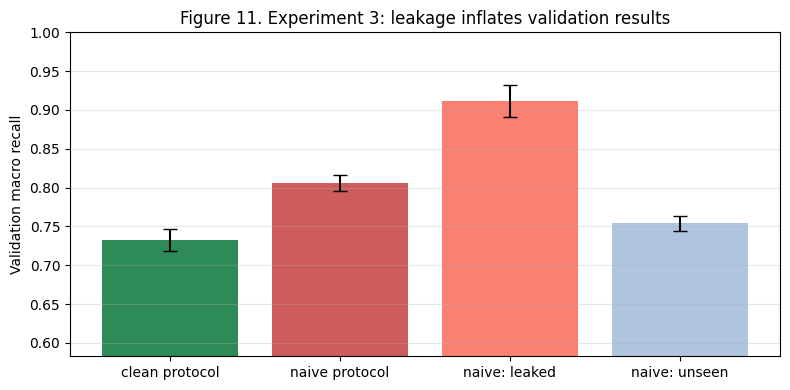

In [24]:
# Same baseline settings, naive data
run_config("E3_naive_split", {}, data=DATA_NAIVE, extra_eval=leak_breakdown)

# Clean vs naive protocol
e3 = summarize(["S1_baseline", "E3_naive_split"], ["macro_recall", "macro_f1", "accuracy", "tumor_fnr", "gap"])
print("Validation results under each protocol (same baseline configuration, 3 seeds):")
display(format_summary(e3).set_axis(["Clean, group-aware (ours)", "Naive random split of raw data"]))

# Leaked vs unseen images in the naive validation set
naive_rows = pd.DataFrame([r for r in RUNS if r["config"] == "E3_naive_split"])
breakdown = pd.DataFrame({
    "macro recall": [f"{naive_rows[f'macro_recall_{p}'].mean():.3f} ± {naive_rows[f'macro_recall_{p}'].std():.3f}"
                     for p in ("leaked", "unseen")],
    "accuracy": [f"{naive_rows[f'accuracy_{p}'].mean():.3f} ± {naive_rows[f'accuracy_{p}'].std():.3f}"
                 for p in ("leaked", "unseen")],
    "images": [int(NAIVE_LEAKED.sum()), int((~NAIVE_LEAKED).sum())],
}, index=["leaked (related image in training)", "unseen"])
print("Inside the naive validation set:")
display(breakdown)

# Figure 11: the four macro recall values
fig, ax = plt.subplots(figsize=(8, 4))
vals = [e3.loc["S1_baseline", ("macro_recall", "mean")], e3.loc["E3_naive_split", ("macro_recall", "mean")],
        naive_rows["macro_recall_leaked"].mean(), naive_rows["macro_recall_unseen"].mean()]
errs = [e3.loc["S1_baseline", ("macro_recall", "std")], e3.loc["E3_naive_split", ("macro_recall", "std")],
        naive_rows["macro_recall_leaked"].std(), naive_rows["macro_recall_unseen"].std()]
ax.bar(["clean protocol", "naive protocol", "naive: leaked", "naive: unseen"], vals, yerr=errs, capsize=5,
       color=["seagreen", "indianred", "salmon", "lightsteelblue"])
ax.set_ylabel("Validation macro recall")
ax.set_ylim(max(0.0, min(vals) - 0.15), 1.0)
ax.set_title("Figure 11. Experiment 3: leakage inflates validation results")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig11_exp3_leakage.png", dpi=150)
plt.show()

**Experiment 3 interpretation:** Leakage inflates the results clearly, and the inflation comes from the leaked images.

- **Two protocols.** The naive random split of the raw Training folder reports macro recall **0.806 ± 0.010**, against **0.733 ± 0.014** for our clean protocol, which is 0.073 higher. Accuracy shows the same pattern (0.801 vs 0.716), and the naive tumor false negative rate looks better (0.042 vs 0.095).
- **Inside the naive validation set.** 156 of 431 images (36.2%) have a related image in the naive training set, and 27 have an identical-hash copy. On these **leaked** images, the same models score **0.911 ± 0.020** macro recall; on the **unseen** images they score only **0.754 ± 0.010**. This comparison uses the same trained models, so the 0.157 difference is a direct measure of how much recognizing already-seen images helps.
- **Why the two comparisons differ in strength.** The two-protocol comparison uses different validation images and different training sets (the naive training set is larger, about 2,440 images vs 1,807), so it is only indicative. The leaked vs unseen comparison is direct. The unseen score (0.754) is close to our clean score (0.733), and the small difference fits the larger naive training set. This suggests our clean protocol measures what it should: performance on images the model has not effectively seen.
- **Meaning.** Results published on this dataset with random splits, or on the original Testing folder (67% copies), probably overstate real performance. For our project, this is the strongest evidence that the cleaning and group-aware split were worth the effort.

## 7.2 Experiment Summary

In [25]:
# Every configuration, without duplicates
ALL_NAMES = list(dict.fromkeys(E1_NAMES + E2_NAMES + ["E3_naive_split"]))
summary_all = summarize(ALL_NAMES, ["macro_recall", "macro_f1", "tumor_fnr", "gap", "best_epoch"])
summary_table = format_summary(summary_all)
# Add the settings that define each configuration
summary_table.insert(0, "weight decay", [CONFIGS[n]["weight_decay"] for n in ALL_NAMES])
summary_table.insert(0, "dropout", [CONFIGS[n]["dropout"] for n in ALL_NAMES])
summary_table.insert(0, "data", ["naive" if n == "E3_naive_split" else "clean" for n in ALL_NAMES])
summary_table["carried forward"] = ["yes" if n == SELECTED else "" for n in ALL_NAMES]
print("All Stage 1 and Stage 2 configurations (validation set, mean ± std over 3 seeds). Test set: not used.")
display(summary_table)
# Save the table to Drive
summary_table.to_csv(RESULTS_DIR / "stage2_summary.csv")

All Stage 1 and Stage 2 configurations (validation set, mean ± std over 3 seeds). Test set: not used.


,data,dropout,weight decay,macro_recall,macro_f1,tumor_fnr,gap,best_epoch,carried forward
config,,,,,,,,,
E1_dropout_0.00,clean,0.00,0.00,0.730 ± 0.038,0.726 ± 0.033,0.052 ± 0.008,0.591 ± 0.054,8.7 ± 2.1,
S1_baseline,clean,0.25,0.00,0.733 ± 0.014,0.708 ± 0.025,0.095 ± 0.027,0.402 ± 0.141,12.0 ± 5.0,yes
E1_dropout_0.50,clean,0.50,0.00,0.702 ± 0.012,0.689 ± 0.013,0.078 ± 0.035,0.324 ± 0.041,29.0 ± 10.1,
E2_p0.25_wd_1e-02,clean,0.25,0.01,0.722 ± 0.012,0.706 ± 0.006,0.080 ± 0.007,0.400 ± 0.020,11.7 ± 1.5,
E2_p0.25_wd_1e-01,clean,0.25,0.10,0.720 ± 0.028,0.712 ± 0.024,0.066 ± 0.008,0.484 ± 0.088,15.0 ± 3.6,
E3_naive_split,naive,0.25,0.00,0.806 ± 0.010,0.799 ± 0.014,0.042 ± 0.013,0.315 ± 0.006,12.7 ± 1.5,


All clean-protocol configurations land between 0.702 and 0.733 validation macro recall, and most differences are within one or two seed standard deviations. Regularization mainly changed **how** the model overfits (dropout reduced the gap from 0.591 to 0.324), not **how well** it generalizes. The change with by far the largest effect was the **data protocol**: the naive split adds 0.073 macro recall that is not real. The baseline configuration (dropout 0.25, no weight decay) is carried forward.

## 7.3 Generalization and Diagnostic Analysis

We compare the **baseline** with the **selected configuration** using diagnostics that go beyond macro recall: confusion matrices, the tumor detection metrics per tumor type, calibration, and the misclassified images. Single-run plots use seed 42; tables use the mean over three seeds.

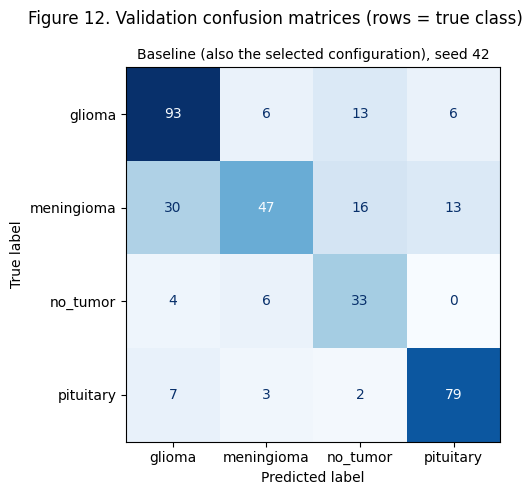

Clinical view (validation, mean ± std over 3 seeds). fnr_<type> = share of that tumor type predicted as no tumor.


,Baseline (also the selected configuration)
tumor_sensitivity,0.905 ± 0.027
tumor_fnr,0.095 ± 0.027
fnr_glioma,0.082 ± 0.035
fnr_meningioma,0.179 ± 0.057
fnr_pituitary,0.015 ± 0.006
no_tumor_specificity,0.798 ± 0.075
macro_recall,0.733 ± 0.014
ece,0.081 ± 0.019


Selected configuration, per-class validation metrics (mean ± std over 3 seeds):


,precision,recall,F1
glioma,0.780 ± 0.075,0.718 ± 0.072,0.743 ± 0.018
meningioma,0.669 ± 0.077,0.569 ± 0.133,0.604 ± 0.058
no_tumor,0.540 ± 0.056,0.798 ± 0.075,0.641 ± 0.025
pituitary,0.843 ± 0.043,0.846 ± 0.038,0.843 ± 0.007


In [26]:
# Baseline vs selected configuration
y_val = DATA_CLEAN["y_val_np"]
if SELECTED == "S1_baseline":
    compare = {"Baseline (also the selected configuration)": "S1_baseline"}
else:
    compare = {"Baseline": "S1_baseline", f"Selected ({SELECTED})": SELECTED}

# Figure 12: confusion matrices (seed 42)
fig, axes = plt.subplots(1, len(compare), figsize=(6 * len(compare), 5), squeeze=False)
axes = axes.ravel()
for ax, (label, name) in zip(axes, compare.items()):
    pred = VAL_PROBS[(name, SEED)].argmax(axis=1)
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred, labels=list(range(len(CLASSES)))),
                           display_labels=SHORT_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{label}, seed {SEED}", fontsize=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.suptitle("Figure 12. Validation confusion matrices (rows = true class)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig12_confusion_matrices.png", dpi=150)
plt.show()

# Tumor detection metrics, overall and per tumor type
clin_cols = ["tumor_sensitivity", "tumor_fnr"] + [f"fnr_{SHORT_NAMES[c]}" for c in TUMOR_IDX] + \
            ["no_tumor_specificity", "macro_recall", "ece"]
clinical = format_summary(summarize(list(compare.values()), clin_cols)).set_axis(list(compare.keys())).T
print("Clinical view (validation, mean ± std over 3 seeds). fnr_<type> = share of that tumor type predicted as no tumor.")
display(clinical)

# Per-class metrics of the selected configuration
sel_rows = pd.DataFrame([r for r in RUNS if r["config"] == SELECTED])
sel_per_class = pd.DataFrame({
    c: [f"{sel_rows[f'{m}_{c}'].mean():.3f} ± {sel_rows[f'{m}_{c}'].std():.3f}" for m in ("precision", "recall", "f1")]
    for c in SHORT_NAMES}, index=["precision", "recall", "F1"]).T
print("Selected configuration, per-class validation metrics (mean ± std over 3 seeds):")
display(sel_per_class)

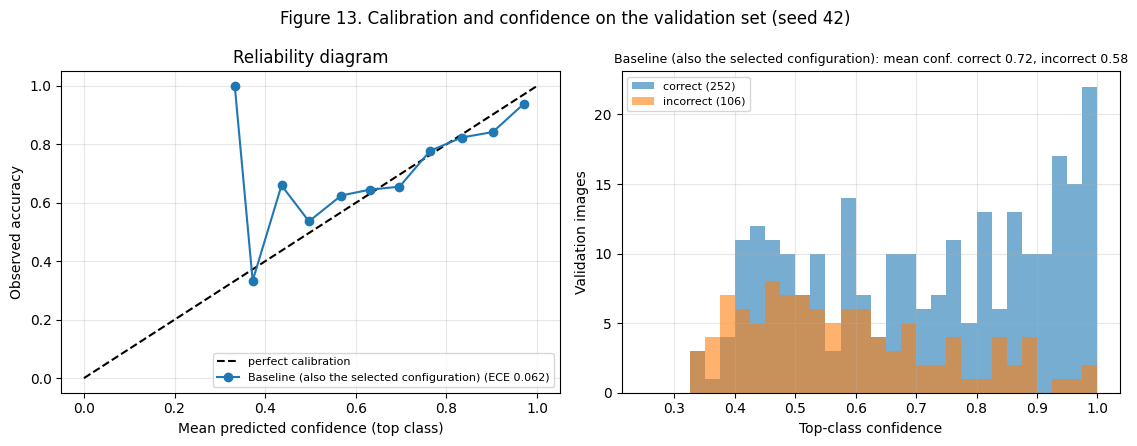

In [27]:
# Calibration: reliability diagram and
# confidence of correct vs incorrect predictions (seed 42)
def reliability_curve(y_true, probs, n_bins=15):
    # Mean confidence and accuracy in each bin
    conf, correct = probs.max(axis=1), probs.argmax(axis=1) == y_true
    edges = np.linspace(0, 1, n_bins + 1)
    centers, accs, counts = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            centers.append(conf[m].mean())
            accs.append(correct[m].mean())
            counts.append(m.sum())
    return np.array(centers), np.array(accs), np.array(counts)


# Left panel: reliability diagram
fig, axes = plt.subplots(1, 1 + len(compare), figsize=(5.7 * (1 + len(compare)), 4.5))
axes[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
for label, name in compare.items():
    probs = VAL_PROBS[(name, SEED)]
    centers, accs, counts = reliability_curve(y_val, probs)
    axes[0].plot(centers, accs, marker="o", label=f"{label} (ECE {expected_calibration_error(y_val, probs):.3f})")
axes[0].set_xlabel("Mean predicted confidence (top class)")
axes[0].set_ylabel("Observed accuracy")
axes[0].set_title("Reliability diagram")
axes[0].legend(fontsize=8)

# Right panel: confidence histograms
for ax, (label, name) in zip(axes[1:], compare.items()):
    probs = VAL_PROBS[(name, SEED)]
    conf, correct = probs.max(axis=1), probs.argmax(axis=1) == y_val
    ax.hist(conf[correct], bins=np.linspace(0.25, 1, 31), alpha=0.6, label=f"correct ({correct.sum()})")
    ax.hist(conf[~correct], bins=np.linspace(0.25, 1, 31), alpha=0.6, label=f"incorrect ({(~correct).sum()})")
    ax.set_xlabel("Top-class confidence")
    ax.set_ylabel("Validation images")
    ax.set_title(f"{label}: mean conf. correct {conf[correct].mean():.2f}, incorrect {conf[~correct].mean():.2f}",
                 fontsize=9)
    ax.legend(fontsize=8)
for a in axes:
    a.grid(alpha=0.3)
plt.suptitle(f"Figure 13. Calibration and confidence on the validation set (seed {SEED})")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig13_calibration.png", dpi=150)
plt.show()

Validation errors: 106 of 358; missed tumors (predicted no tumor): 31
Error pairs (true -> predicted):


,count
meningioma -> glioma,30
meningioma -> no_tumor,16
glioma -> no_tumor,13
meningioma -> pituitary,13
pituitary -> glioma,7
glioma -> pituitary,6
glioma -> meningioma,6
no_tumor -> meningioma,6
no_tumor -> glioma,4
pituitary -> meningioma,3


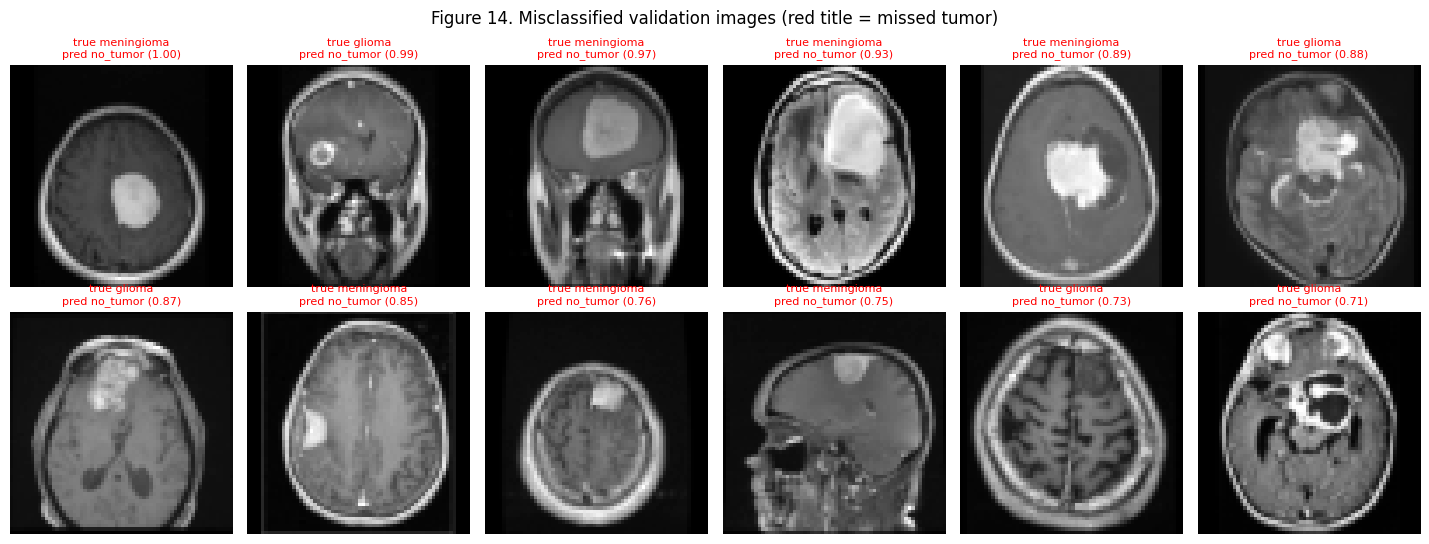

In [28]:
# Misclassified validation images (seed 42).
# Missed tumors are shown first,
# then the most confident other errors.
probs = VAL_PROBS[(SELECTED, SEED)]
pred, conf = probs.argmax(axis=1), probs.max(axis=1)
# Indices of all errors and of missed tumors
wrong = np.where(pred != y_val)[0]
missed = wrong[(y_val[wrong] != NO_TUMOR) & (pred[wrong] == NO_TUMOR)]
others = np.setdiff1d(wrong, missed)
order = list(missed[np.argsort(-conf[missed])]) + list(others[np.argsort(-conf[others])])
show = order[:12]
print(f"Validation errors: {len(wrong)} of {len(y_val)}; missed tumors (predicted no tumor): {len(missed)}")
print("Error pairs (true -> predicted):")
display(pd.Series([f"{SHORT_NAMES[y_val[i]]} -> {SHORT_NAMES[pred[i]]}" for i in wrong]).value_counts().to_frame("count"))

# Grid of up to 12 errors
if show:
    cols = 6
    rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.4 * cols, 2.8 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        img_id = DATA_CLEAN["val_idx"][i]
        ax.imshow(IMG64[img_id], cmap="gray")
        color = "red" if i in set(missed) else "black"
        ax.set_title(f"true {SHORT_NAMES[y_val[i]]}\npred {SHORT_NAMES[pred[i]]} ({conf[i]:.2f})", fontsize=8, color=color)
    plt.suptitle("Figure 14. Misclassified validation images (red title = missed tumor)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig14_misclassified.png", dpi=150)
    plt.show()

### Shortcut Check: Does Image Format Predict the Label?

Section 5.2 showed that almost every tumor image is 512 × 512, while almost no no-tumor image is. The no-tumor images also look like they come from different sources (different contrasts, planes, and even a CT-like scan in Figure 3). A model could learn "this does not look like the usual 512 × 512 scan, so it is no tumor" instead of looking for a lesion. We test this in two ways on the validation set: (1) how well a trivial rule, *"not 512 × 512 → no tumor"*, performs with no learning at all; and (2) whether the selected model's errors depend on the native format.

In [29]:
# Native size and correctness per validation image
val_meta = df.loc[DATA_CLEAN["val_idx"], ["class", "size"]].reset_index(drop=True)
val_meta["is_512"] = val_meta["size"] == "512x512"
val_meta["correct"] = pred == y_val
val_meta["missed_tumor"] = (y_val != NO_TUMOR) & (pred == NO_TUMOR)

# (1) Trivial rule: predict no tumor
# if and only if the image is not 512 x 512
rule_no_tumor = ~val_meta["is_512"].to_numpy()
true_no_tumor = y_val == NO_TUMOR
SHORTCUT_RULE = {
    "no_tumor recall of the rule": float(rule_no_tumor[true_no_tumor].mean()),
    "no_tumor precision of the rule": float(true_no_tumor[rule_no_tumor].mean()) if rule_no_tumor.any() else float("nan"),
    "tumor images that are not 512x512": int((~true_no_tumor & rule_no_tumor).sum()),
    "no-tumor images that are 512x512": int((true_no_tumor & ~rule_no_tumor).sum()),
}
print("Trivial format rule on the validation set (no model involved):")
display(pd.Series(SHORTCUT_RULE).to_frame("value"))

# (2) Selected model (seed 42):
# error rate by class and native format
SHORTCUT_TABLE = (val_meta.groupby(["class", "is_512"])
                  .agg(images=("correct", "size"),
                       error_rate=("correct", lambda s: 1 - s.mean()),
                       predicted_no_tumor=("missed_tumor", "mean"))
                  .round(3))
print("Selected configuration: validation error rate by class and native format "
      "(predicted_no_tumor applies to tumor classes only):")
display(SHORTCUT_TABLE)
# How many missed tumors are not 512 x 512
missed_meta = val_meta[val_meta["missed_tumor"]]
print(f"Missed tumors: {len(missed_meta)}; of these, not 512x512: {int((~missed_meta['is_512']).sum())}")

Trivial format rule on the validation set (no model involved):


,value
no_tumor recall of the rule,1.000000
no_tumor precision of the rule,0.573333
tumor images that are not 512x512,32.000000
no-tumor images that are 512x512,0.000000


Selected configuration: validation error rate by class and native format (predicted_no_tumor applies to tumor classes only):


images  error_rate  predicted_no_tumor
class      is_512                                        
glioma     False       10       1.000               0.800
           True       108       0.139               0.046
meningioma False       19       0.737               0.526
           True        87       0.517               0.069
no_tumor   False       43       0.233               0.000
pituitary  False        3       0.000               0.000
           True        88       0.136               0.023

Missed tumors: 31; of these, not 512x512: 18


### Diagnostic Interpretation

- **Confusions are asymmetric (Figure 12, seed 42).** The largest error is **meningioma predicted as glioma** (30 images), while glioma is predicted as meningioma only 6 times. Meningioma is also often predicted as no tumor (16) and as pituitary (13), so in this run only 47 of 106 meningiomas (44%) were classified correctly. Pituitary is the most reliable class (79 of 91 correct).
- **Missed tumors.** Across three seeds, the tumor false negative rate is 0.095 ± 0.027. By type, it is **0.179 ± 0.057 for meningioma**, 0.082 ± 0.035 for glioma, and only 0.015 ± 0.006 for pituitary. No tumor has a recall of 0.798 but a precision of 0.540, because tumor images are pushed into the no-tumor class (31 of them in seed 42).
- **Calibration (Figure 13).** ECE is 0.081 ± 0.019 (0.062 for seed 42), so the probabilities are roughly calibrated. The model is slightly under-confident between about 0.4 and 0.6 confidence and slightly over-confident at the top (for example, about 0.97 confidence for 0.94 accuracy). Correct predictions have higher mean confidence (0.72) than errors (0.58), so confidence carries useful signal. However, there are **confident errors**: several missed tumors were predicted as no tumor with confidence 0.85 to 1.00 (Figure 14).
- **What the missed tumors have in common (Figure 14).** Many show large, bright, obvious lesions, so the model is not missing them because they are subtle. Most are axial slices with a contrast or crop that differs from the typical 512 × 512 T1 scan, and some have visible frame borders.
- **Shortcut check.** The trivial rule "not 512 × 512 → no tumor" finds **all 43** no-tumor validation images (recall 1.000) with precision 0.573, without any learning. The model's errors follow the same pattern. Gliomas that are not 512 × 512 (10 images) were all misclassified, and 80% of them were called no tumor, against 4.6% for 512 × 512 gliomas. For meningioma, 52.6% of non-512 images were called no tumor, against 6.9% of 512 × 512 ones. **18 of the 31 missed tumors are non-512 images, although only 32 of the 315 tumor images in validation (10%) are non-512.** The evidence strongly suggests that the MLP partly uses acquisition style (size, contrast, source) as a cue for "no tumor". This is a property of the dataset, so it will affect every model trained on it, not only the MLP.
- **Decision and link to Stage 3.** We carry forward the baseline configuration. Stage 3 must answer two questions: (1) does a model that can see local shape (a CNN) separate meningioma from glioma better; and (2) does it look at the lesion or at the image style? Grad-CAM and metrics reported separately for 512 × 512 and non-512 images will test the second question.

## 7.4 Saved Artifacts and Results Digest

The next cell saves all run metrics and training histories to Google Drive and prints a compact digest of every number used in the written interpretations.

In [30]:
# Save run metrics, histories, and configs to Drive
runs_df = pd.DataFrame(RUNS)
runs_df.to_csv(RESULTS_DIR / "runs.csv", index=False)
with open(RESULTS_DIR / "histories.json", "w") as f:
    json.dump({f"{k[0]}|seed{k[1]}": v for k, v in HISTORIES.items()}, f)
with open(RESULTS_DIR / "configs.json", "w") as f:
    json.dump(CONFIGS, f, indent=2, default=str)

print("=" * 90)
print("RESULTS DIGEST")
print("=" * 90)
# Every number used in the written interpretations
print(f"Device: {DEVICE}; total training time: {runs_df.train_seconds.sum() / 60:.1f} min over {len(runs_df)} runs")
print("\n[Raw data]")
print(class_table.to_string())
print(f"Distinct sizes: {df['size'].nunique()}; 512x512 share: {(df['size'] == '512x512').mean():.3f}")
print("\n[Exact duplicates]")
print(exact_summary.to_string())
print("\n[Near duplicates]")
print(near_summary.to_string())
print("\n[Related-threshold sweep]")
print(sweep_df.to_string())
print(f"Selected related threshold: {RELATED_T}")
print(f"\n[Testing folder copies of Training images] {TESTING_COPIES}")
print(testing_copy_table.to_string())
print("\n[Removed by rule]")
print(pd.crosstab(removed.drop_reason, removed.folder, margins=True).to_string())
print("\n[Before and after cleaning]")
print(cleaning_table.to_string())
print("\n[Final split]")
print(split_table.to_string())
print("\n[Origin of each split]")
print(origin_table.to_string())
print("\n[Residual similarity]")
print(residual.to_string())
print("\n[All configurations, validation]")
print(summary_table.to_string())
print("\n[Experiment 1]")
print(format_summary(e1_summary).to_string())
print("\n[Experiment 2]")
print(format_summary(e2_summary).to_string())
print(f"Best Exp 1: {BEST_E1}; selected overall: {SELECTED}")
print("\n[Experiment 3]")
print(leak_table.to_string())
print(format_summary(e3).to_string())
print(breakdown.to_string())
print("\n[Clinical view]")
print(clinical.to_string())
print("\n[Per-class: baseline]")
print(per_class.to_string())
print("\n[Per-class: selected]")
print(sel_per_class.to_string())
print(f"\n[Errors, selected seed {SEED}] {len(wrong)} of {len(y_val)}; missed tumors: {len(missed)}")
print(pd.Series([f"{SHORT_NAMES[y_val[i]]} -> {SHORT_NAMES[pred[i]]}" for i in wrong]).value_counts().to_string())
print("\n[Shortcut check]")
print(pd.Series(SHORTCUT_RULE).to_string())
print(SHORTCUT_TABLE.to_string())
print(f"Missed tumors not 512x512: {int((~missed_meta['is_512']).sum())} of {len(missed_meta)}")
print("\n[Per-run rows]")
print(runs_df[["config", "seed", "best_epoch", "epochs_run", "gap", "macro_recall", "macro_f1",
               "tumor_fnr", "ece", "train_seconds"]].round(4).to_string())

RESULTS DIGEST
Device: cuda; total training time: 1.2 min over 18 runs

[Raw data]
folder      Training  Testing  Total  Training %  Testing %
class                                                      
glioma           826      100    926        28.8       25.4
meningioma       822      115    937        28.6       29.2
no_tumor         395      105    500        13.8       26.6
pituitary        827       74    901        28.8       18.8
Total           2870      394   3264       100.0      100.0
Distinct sizes: 440; 512x512 share: 0.717

[Exact duplicates]
files in exact-duplicate groups          403
exact-duplicate groups                   166
redundant copies (files minus groups)    237
groups inside Training only               61
groups inside Testing only                41
groups shared by Training and Testing     64
groups with conflicting labels             0

[Near duplicates]
near-duplicate clusters (size > 1)                       450
images in those clusters                

# 8. Challenges and Mitigation

### Challenge 1: Duplicates and no patient IDs (data quality and leakage)

- **How it affected the project:** the raw data contains exact and near-duplicate images, some shared between the Training and Testing folders, and there are no patient IDs. A random split would let the model "recognize" images instead of learning to classify them, which overstates performance (Yagis et al., 2021). Experiment 3 measures this effect directly: a naive split reports 0.806 macro recall instead of 0.733, and leaked images score 0.911 against 0.754 for unseen ones.
- **What we did:** we ran an MD5 and pHash audit before any split, removed label conflicts and every redundant copy (including Testing copies of Training images), grouped visually related images with a threshold chosen by a sweep, and built a stratified, group-aware train, validation, and test split from the cleaned images of both folders. The audit showed that the predefined Testing folder could not serve as a test set: 67% of it copies Training images, and no no-tumor image was left after cleaning.
- **Was it effective:** partly. No validation or test image is within 6 bits of a training image, but 64% of validation and 65% of test images are within 10 bits (Figure 7). A stricter threshold (8 bits) was not usable, because it chained 120 images into one group.
- **Further action:** pHash only captures coarse visual similarity, so different slices or planes of the same patient can still look different and end up in different splits. We will state this limitation in the final results and treat our test score as an upper estimate of performance on new patients.

### Challenge 2: Class imbalance and distribution shift

- **How it affected the project:** no tumor has about half the images of each tumor class in the Training folder, and its share is much higher in the Testing folder. Accuracy alone would reward a model that ignores the smallest class.
- **What we did:** inverse-frequency class weights in the loss; macro recall as the primary metric; per-class metrics, no-tumor specificity, and tumor FNR in every comparison; a stratified split.
- **Was it effective:** yes for recall. No tumor, the smallest class, reaches a recall of 0.798, higher than glioma (0.718) and meningioma (0.569), and the split keeps its share at about 12% in every part. The cost is a low no-tumor precision (0.540): the weighted loss, together with the format shortcut, pushes some tumor images into the no-tumor class.
- **Further action:** our stratified split gives the same class mix in train, validation, and test, so the shift between the original folders no longer affects the evaluation. A real clinic would have a different class mix again, so we will keep reporting per-class metrics rather than accuracy alone.

### Challenge 3: A small dataset for a dense model (overfitting)

- **How it affected the project:** only 1,807 training images after cleaning, for a dense network that treats every pixel as a separate input. The proposed 2.3M-parameter MLP was likely to memorize the training set.
- **What we did:** reduced the MLP to about 1.08M parameters, used early stopping with best-weight restore, and tested dropout and weight decay in Experiments 1 and 2.
- **Was it effective:** only partly. Dropout cut the gap from 0.591 (p = 0) to 0.402 (p = 0.25) and 0.324 (p = 0.5), but p = 0.5 lowered macro recall to 0.702, and weight decay did not help. Training recall still reaches about 0.9 while validation recall stays near 0.73.
- **Further action:** the MLP must learn a separate weight for every pixel position, so regularization alone cannot remove this limit. The weight sharing of a CNN in Stage 3 is the structural fix.

### Challenge 4: Heterogeneous images

- **How it affected the project:** hundreds of native sizes, three imaging planes, and several MRI contrasts. For an MLP, the same anatomy appears at different pixel positions in different images.
- **What we did:** a fixed preprocessing pipeline (grayscale, empty-border crop, square padding, and resize) that removes border and size differences without distorting the anatomy.
- **Was it effective:** for size, yes; for source, no. The shortcut check (Section 7.3) shows that 18 of the 31 missed tumors are non-512 images, although they are only 10% of the tumor images. Resizing removes the size difference, but the contrast and style differences that come with it remain.
- **Further action:** data augmentation for the Stage 3 CNN (small rotations, flips, mild scaling, brightness and contrast changes), Grad-CAM to check where the CNN looks, and metrics reported separately for 512 × 512 and non-512 images.

### Challenge 5: Framework mismatch with the course material

- **How it affected the project:** the course template and labs use TensorFlow/Keras, while our approved proposal uses PyTorch. Template cells and course code could not be reused directly.
- **What we did:** we adapted the template cells to PyTorch and documented the equivalent choices (for example, raw logits with `nn.CrossEntropyLoss` instead of a softmax output layer, and `AdamW` with zero weight decay as Adam).
- **Was it effective:** yes. The notebook runs end to end, and the PyTorch logits issue raised in the feedback is resolved.
- **Further action:** none beyond keeping the same conventions in Stage 3.

### Challenge 6: Compute limits and reproducibility on Colab

- **How it affected the project:** Colab sessions can disconnect, GPU time is limited, and GPU training is not always bit-for-bit reproducible.
- **What we did:** small 64 × 64 inputs and in-memory tensors (each run takes seconds); fixed seeds and deterministic settings; three seeds per configuration; results, figures, and checkpoints saved to Google Drive; a saved split manifest.
- **Was it effective:** yes. All 18 runs took 1.2 minutes of GPU time in total. The seed-to-seed standard deviation of macro recall is 0.012 to 0.038, which shows why we always compare means over three seeds rather than single runs.
- **Further action:** Stage 3 uses 224 × 224 images and larger models, so we will cache the preprocessed images and save a checkpoint each epoch to resume after a disconnect.

### Challenge 7: An experiment that could not show an effect

- **How it affected the project:** in our first run, the proposed weight decay values (1e-4 and 1e-3) produced loss curves that overlapped the curve without weight decay, so Experiment 2 could not answer its question.
- **What we did:** we checked the AdamW update rule. The per-step shrink is learning rate × weight decay, so these values changed the weights by about 0.2% or less over a whole run. We moved the grid to 1e-2 and 1e-1.
- **Was it effective:** yes. The new values change model behaviour measurably (for example, the tumor false negative rate fell from 0.095 to 0.066 at 1e-1, while no-tumor specificity fell from 0.798 to 0.682), even though they did not improve macro recall. The experiment can now answer its question.
- **Further action:** check the scale of every hyperparameter against the update rule before running an experiment, not only against values used in other papers.

### Challenge 8: Team coordination and scope

- **How it affected the project:** three members with different schedules, and a proposal with more experiments than the timeline allows.
- **What we did:** regular meetings with a written action list (four between the feedback and the checkpoint), a shared task board, a team chat for daily updates, a rule that every reported result is reproduced by a second member, and a reduced Stage 2 scope based on the feedback.
- **Was it effective:** the midterm scope was finished on time with all three members contributing (Section 2).
- **Further action:** freeze the Stage 3 scope (custom CNN, then one ResNet18 experiment) and start the ethics presentation research in parallel from Week 10.

# 9. Midterm Reflection and Forward Plan

**What changed the project most.** The most influential decision was not a model setting but the data protocol. The audit showed that 67% of the official Testing folder copies Training images, and Experiment 3 showed that a naive random split adds 0.073 macro recall that is not real (leaked images 0.911 vs unseen 0.754). Building a cleaned, group-aware split before training changed what our numbers mean. We now trust them more, even though they are lower. The regularization experiments mattered much less. Dropout reduced the train-validation gap from 0.591 to 0.324, but no setting beat the baseline's 0.733 macro recall, and weight decay at 1e-2 or 1e-1 did not help.

**What the evidence says about the model.** The MLP overfits within about 7 to 17 epochs and reaches a ceiling of about 0.73 macro recall. It handles pituitary tumors well (recall 0.846) but struggles with meningioma (recall 0.569, missed as no tumor 17.9% of the time), which it often confuses with glioma. The shortcut check gives the most worrying finding: 18 of the 31 missed tumors are non-512 images, and the trivial rule "not 512 × 512 → no tumor" already finds every no-tumor image. Part of what the model learns is image style, not anatomy.

**Remaining limitations.** No patient IDs, so some related slices may still cross splits (about 64% of validation images are within 10 pHash bits of a training image). The no-tumor class is confounded with its source. Results come from one split, and the confident missed tumors mean the probabilities are not safe to use as a screening score.

**Stage 3 direction and why.** The images are spatial data, and the MLP's main weaknesses (position-specific weights, no local shape features, confusion between tumor types) are exactly what convolution addresses. We will follow two directions:

1. **Custom CNN:** three or four blocks of 3 × 3 convolution, batch normalization (Ioffe & Szegedy, 2015), ReLU, and max pooling, then global average pooling, on 224 × 224 inputs, with training-only augmentation (rotation, flips, scaling, brightness and contrast) and dropout 0.25 from Stage 2.
2. **One controlled ResNet18 transfer learning experiment (He et al., 2016):** a frozen feature extractor first, then fine-tuning with a small learning rate. ImageNet features (Deng et al., 2009) should help with only 1,807 training images.

Both will be compared with the MLP on the same validation split. Grad-CAM (Selvaraju et al., 2017), plus metrics reported separately for 512 × 512 and non-512 images, will test whether the gains come from the lesion or from image style.

**Remaining work and organization.** Weeks 9 and 10: 224 × 224 cache, augmentation, and the custom CNN (Kritika). Weeks 10 and 11: the ResNet18 experiment (Chirag). Weeks 12 and 13: Grad-CAM, the cross-stage comparison, and the single final test evaluation (Dhrumil). Week 14: the ethics presentation, where shortcut learning and leakage are strong candidate topics (all). Week 15: the final notebook and demo (all). We keep the weekly meetings, the shared task board, and the rule that a second member reproduces every reported result.

---

## Midterm Checkpoint Review

- [x] Sections 1 to 9 are complete, and all interpretations are based on the outputs.
- [x] The baseline and at least two structured experiments are documented.
- [x] Metrics and visualizations are interpreted.
- [x] The forward plan is supported by evidence.
- [x] The team meeting record and individual contribution table are accurate.
- [x] Important files and checkpoints are stored on Google Drive.
- [x] The notebook contains no credentials or private information.
- [x] The file opens correctly and uses the `.ipynb` extension.

*Work below this line continues after the Midterm Checkpoint.*

---

# 10. Stage 3: Architectural Specialization

*To be completed after the midterm checkpoint (Weeks 9 to 13), following the plan in Section 9.*

## 10.1 Architecture Selection and Rationale

## 10.2 Training Strategy

## 10.3 Specialized Model Evaluation

### Specialized Model Interpretation

# 11. Final Comparison and Key Findings

*To be completed for the final submission.*

## 11.1 Comparison Across Stages

| Stage/model | Primary metric(s) | Generalization evidence | Training/resource cost | Main strength | Main limitation |
|---|---:|---|---|---|---|
| Stage 1 baseline | | | | | |
| Best Stage 2 model | | | | | |
| Stage 3 model | | | | | |

## 11.2 Key Findings

# 12. Limitations and Responsible Use

*To be completed for the final submission.*

## 12.1 Limitations

## 12.2 Responsible Use

# 13. Project Reflection and Future Work

*To be completed for the final submission.*

# 14. References

Bhuvaji, S., Kadam, A., Bhumkar, P., Dedge, S., & Kanchan, S. (2025). *Brain tumor classification (MRI)* (Version 3) [Data set]. Kaggle. https://doi.org/10.34740/kaggle/dsv/12745533

Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In *2009 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 248–255). IEEE. https://doi.org/10.1109/CVPR.2009.5206848

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. In *Proceedings of the 34th International Conference on Machine Learning* (pp. 1321–1330). PMLR. https://proceedings.mlr.press/v70/guo17a.html

He, K., Zhang, X., Ren, S., & Sun, J. (2015). Delving deep into rectifiers: Surpassing human-level performance on ImageNet classification. In *Proceedings of the IEEE International Conference on Computer Vision* (pp. 1026–1034). IEEE. https://doi.org/10.1109/ICCV.2015.123

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). IEEE. https://doi.org/10.1109/CVPR.2016.90

Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. In *Proceedings of the 32nd International Conference on Machine Learning* (pp. 448–456). PMLR. https://proceedings.mlr.press/v37/ioffe15.html

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980

LeCun, Y., Bengio, Y., & Hinton, G. (2015). Deep learning. *Nature, 521*(7553), 436–444. https://doi.org/10.1038/nature14539

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. In *International Conference on Learning Representations*. https://arxiv.org/abs/1711.05101

Louis, D. N., Perry, A., Wesseling, P., Brat, D. J., Cree, I. A., Figarella-Branger, D., Hawkins, C., Ng, H. K., Pfister, S. M., Reifenberger, G., Soffietti, R., von Deimling, A., & Ellison, D. W. (2021). The 2021 WHO classification of tumors of the central nervous system: A summary. *Neuro-Oncology, 23*(8), 1231–1251. https://doi.org/10.1093/neuonc/noab106

Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., . . . Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. In *Advances in Neural Information Processing Systems 32*. Curran Associates. https://arxiv.org/abs/1912.01703

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Raghu, M., Zhang, C., Kleinberg, J., & Bengio, S. (2019). Transfusion: Understanding transfer learning for medical imaging. In *Advances in Neural Information Processing Systems 32*. Curran Associates. https://arxiv.org/abs/1902.07208

scikit-learn developers. (n.d.). *StratifiedGroupKFold*. scikit-learn documentation. Retrieved October 30, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html

Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. In *Proceedings of the IEEE International Conference on Computer Vision* (pp. 618–626). IEEE. https://doi.org/10.1109/ICCV.2017.74

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html

Yagis, E., Atnafu, S. W., García Seco de Herrera, A., Marzi, C., Scheda, R., Giannelli, M., Tessa, C., Citi, L., & Diciotti, S. (2021). Effect of data leakage in brain MRI classification using 2D convolutional neural networks. *Scientific Reports, 11*, Article 22544. https://doi.org/10.1038/s41598-021-01681-w

Zauner, C. (2010). *Implementation and benchmarking of perceptual image hash functions* [Master's thesis, Upper Austria University of Applied Sciences, Hagenberg Campus]. https://www.phash.org/docs/pubs/thesis_zauner.pdf

**Code acknowledgement.** All code in this notebook was written by the team for this project. The pHash function follows the standard DCT-based method described by Zauner (2010). The group-aware split uses scikit-learn's `StratifiedGroupKFold` as documented. The training-loop structure and metric choices follow the course Modules 3 to 8.

# 15. Submission Checklists

## Final submission (Week 15)

### Content

- [ ] All three project stages are complete.
- [ ] Major modeling decisions are explained and justified.
- [ ] Experiments are controlled and documented.
- [ ] Metrics, tables, and visualizations are interpreted.
- [ ] Earlier models are compared with the final model.
- [ ] Key findings are supported by evidence.
- [ ] Limitations and responsible-use considerations are addressed.
- [ ] The project reflection and references are complete.

### Technical quality

- [ ] The notebook follows a logical execution order.
- [ ] Required libraries, datasets, paths, and dependencies are documented.
- [ ] Code is readable, modular, and appropriately commented.
- [ ] Figures and tables have clear titles, labels, and legends.
- [ ] Important artifacts are saved outside temporary runtime storage.
- [ ] Unused cells, debugging output, and placeholder instructions are removed.
- [ ] No passwords, API keys, private data, or credentials are included.

### Final verification

- [ ] The notebook has been run from beginning to end when computationally feasible.
- [ ] Saved outputs correspond to the final code and analysis.
- [ ] The final file opens correctly and uses the `.ipynb` extension.
- [ ] The correct file is ready for submission through Canvas.